# Clustering Track - Machine Operating Profile Discovery


# Smart Manufacturing Machine Learning Case Study


## Review 1 & Review 2

This project analyzes a smart manufacturing dataset containing machine,
environmental, production, maintenance, and operational information.

**Team members:** Sai Rakesh Reddy (CB.SC.U4CSE24517), Akhil Reddy (CB.SC.U4CSE24518), and Varanasi Rohit (CB.SC.U4CSE24561).

Two machine learning tasks are performed:

1. Regression — Predict machine energy consumption (`machine_energy_kwh`)
2. Classification — Predict maintenance risk (`maintenance_risk`)

The project covers:
- Exploratory Data Analysis (EDA)
- Data Cleaning
- Missing Value Treatment
- Duplicate Detection
- Outlier Detection
- Feature Engineering
- Categorical Encoding
- Feature Scaling
- Regression
- Classification
- Model Evaluation
- Hyperparameter Tuning
- Cross-Validation

**Review 2 additions (Sections E–G):**
- Classification Part B: Random Forest, AdaBoost, Gradient Boosting, Bagging, MLP
- Consolidated 10-algorithm comparison, cross-validation and final model selection
- Clustering: K-Means (Elbow) and Agglomerative (Dendrograms, linkage comparison)
- Silhouette, Davies-Bouldin and Calinski-Harabasz metrics; PCA and t-SNE visualisations
- Pipeline summary, saved model and results tables


In [1]:
# ================================
# 1. IMPORTS & CONFIGURATION
# ================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder,
    OrdinalEncoder
)

from sklearn.compose import ColumnTransformer

# Reproducibility
RANDOM_STATE = 42

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Plot settings
sns.set_theme(style="whitegrid")
PALETTE = sns.color_palette("colorblind")
sns.set_palette(PALETTE)

print("Libraries imported successfully.")

Libraries imported successfully.


# Section A — Dataset & Exploratory Data Analysis (EDA)

## A1.1 — Dataset Loading & Initial Audit

This phase loads the smart manufacturing sensor dataset containing 22,000 production records to inspect data integrity, schema types, and baseline missing values.


In [2]:
# Load dataset
import os
from pathlib import Path

# Search in data/ directory, parent data/ directory, or current directory
csv_candidates = [
    Path("../data/smart_manufacturing_ml_dataset.csv"),
    Path("data/smart_manufacturing_ml_dataset.csv"),
    Path("smart_manufacturing_ml_dataset.csv"),
]
data_path = next((p for p in csv_candidates if p.exists()), Path("data/smart_manufacturing_ml_dataset.csv"))
df = pd.read_csv(data_path)

print(f"Dataset loaded successfully from: {data_path}")


Dataset loaded successfully from: ..\data\smart_manufacturing_ml_dataset.csv


### A1.2 — Previewing Raw Dataset Observations

This step displays the initial 5 observations to verify column headers and preliminary record contents.


In [3]:
df.head()

,machine_id,plant,production_line,machine_type,shift,operator_experience_years,machine_age_years,ambient_temperature_c,humidity_pct,vibration_mm_s,hydraulic_pressure_bar,motor_current_a,rpm,production_rate_units_hr,defect_rate_pct,downtime_hours_30d,maintenance_count,days_since_maintenance,power_factor,oil_temperature_c,bearing_temperature_c,load_percent,noise_db,material_grade,lubricant_type,supplier_tier,inspection_status,batch_size,machine_energy_kwh,maintenance_risk
0,118835,Chennai,L3,CNC,Afternoon,9.80,12.55,29.25,98.00,3.116,6.53,19.64,2335.8,112.9,2.625,3.48,3,19.7,0.953,51.09,44.25,76.29,74.60,HighStrength,Synthetic,NaN,Rework,344,39.19,Medium
1,100736,Hyderabad,L1,Milling,Afternoon,0.20,9.14,27.87,63.55,2.284,7.81,30.47,2477.5,107.2,1.382,0.81,1,31.0,0.879,60.54,50.44,73.22,69.54,Standard,Synthetic,Local,Pass,382,40.39,Low
2,120211,Ahmedabad,L1,Lathe,Night,9.68,3.82,27.89,57.28,2.662,7.27,32.25,3558.0,146.4,7.156,0.44,1,10.3,0.942,48.81,46.10,80.38,75.77,Standard,Synthetic,Local,Pass,297,47.36,Low
3,118587,Chennai,L5,Robot,Afternoon,10.70,7.11,22.20,68.56,1.457,7.64,38.33,3419.4,94.6,7.787,1.02,1,130.7,0.903,55.07,42.14,71.95,70.10,Recycled,Bio,Tier3,Pass,773,58.99,Medium
4,105358,Pune,L1,Compressor,Morning,5.13,2.73,31.78,79.86,2.873,8.63,30.06,2456.5,78.3,9.551,0.24,1,75.6,0.912,NaN,55.14,58.85,70.34,Recycled,Mineral,Tier2,Pass,984,39.78,High


### A1.3 — Dataset Shape & Dimension Inspection

This step outputs total row counts and feature counts across the uncleaned dataset.


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 22260
Number of columns: 30


### A1.4 — Feature Data Types & Column Schema Audit

This step audits data types across numerical and categorical columns to ensure appropriate formatting.


In [5]:
df.dtypes

machine_id                     int64
plant                         object
production_line               object
machine_type                  object
shift                         object
operator_experience_years    float64
machine_age_years            float64
ambient_temperature_c        float64
humidity_pct                 float64
vibration_mm_s               float64
hydraulic_pressure_bar       float64
motor_current_a              float64
rpm                          float64
production_rate_units_hr     float64
defect_rate_pct              float64
downtime_hours_30d           float64
maintenance_count              int64
days_since_maintenance       float64
power_factor                 float64
oil_temperature_c            float64
bearing_temperature_c        float64
load_percent                 float64
noise_db                     float64
material_grade                object
lubricant_type                object
supplier_tier                 object
inspection_status             object
b

### A1.4.1 — Data Type Summary Counts Distribution

This step aggregates feature data types into counts of float, integer, and object columns.


In [6]:
df.dtypes.value_counts()

float64    18
object      9
int64       3
Name: count, dtype: int64

### A1.5 — Initial Missing Values Audit

This step scans all 31 features for null values to plan subsequent imputation strategies.


In [7]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0].sort_values(ascending=False)

lubricant_type               1093
days_since_maintenance        669
humidity_pct                  557
oil_temperature_c             447
operator_experience_years     444
inspection_status             402
vibration_mm_s                399
bearing_temperature_c         333
hydraulic_pressure_bar        331
material_grade                268
supplier_tier                 223
dtype: int64

In [8]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Percentage", ascending=False)

missing_summary

,Missing Count,Missing Percentage
lubricant_type,1093,4.91
days_since_maintenance,669,3.01
humidity_pct,557,2.50
oil_temperature_c,447,2.01
operator_experience_years,444,1.99
inspection_status,402,1.81
vibration_mm_s,399,1.79
bearing_temperature_c,333,1.50
hydraulic_pressure_bar,331,1.49
material_grade,268,1.20


### A1.6 — Duplicate Records Scan

This step identifies exact duplicated records across the raw manufacturing dataset.


In [9]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 260


### A1.7 — Numerical Feature Descriptive Statistics

This step computes summary statistics (mean, std, min, quartiles, max) for all continuous features.


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
machine_id,22260.0,110999.023001,6351.648929,100001.000,105502.75000,110997.500,116500.2500,122000.000000
operator_experience_years,21816.0,6.475534,3.147727,0.200,4.26000,6.430,8.6200,20.000000
machine_age_years,22260.0,6.381268,3.536081,0.200,3.75750,5.740,8.3300,18.000000
ambient_temperature_c,22260.0,28.998906,4.498104,12.020,25.98000,29.020,32.0500,50.060000
humidity_pct,21703.0,62.135863,14.869514,20.000,51.95000,62.100,72.4100,98.000000
vibration_mm_s,21861.0,2.538027,2.182686,0.207,1.59900,2.213,3.0400,68.854809
hydraulic_pressure_bar,21929.0,7.399726,1.096907,3.000,6.66000,7.400,8.1400,11.650000
motor_current_a,22260.0,31.151957,8.341988,8.000,25.69750,31.180,36.4425,108.516390
rpm,22260.0,2800.749470,550.226441,900.000,2427.40000,2795.350,3171.0250,4500.000000
production_rate_units_hr,22260.0,118.210790,30.285837,25.000,97.80000,118.000,138.2000,288.491168


### A1.8 — Regression Target (machine_energy_kwh) Summary Statistics

This step computes descriptive metrics for the continuous energy consumption target variable.


In [11]:
df["machine_energy_kwh"].describe()

count    22260.000000
mean        51.570762
std         11.139477
min         18.010000
25%         43.760000
50%         50.840000
75%         58.562500
max        107.450000
Name: machine_energy_kwh, dtype: float64

### A1.9 — Numerical Predictor Features Identification

This step identifies and separates all continuous numerical features for subsequent distribution and correlation analysis.


In [12]:
# Identify numerical columns

numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

print("Number of numerical columns:", len(numerical_columns))
print("\nNumerical columns:")
for column in numerical_columns:
    print("-", column)

Number of numerical columns: 21

Numerical columns:
- machine_id
- operator_experience_years
- machine_age_years
- ambient_temperature_c
- humidity_pct
- vibration_mm_s
- hydraulic_pressure_bar
- motor_current_a
- rpm
- production_rate_units_hr
- defect_rate_pct
- downtime_hours_30d
- maintenance_count
- days_since_maintenance
- power_factor
- oil_temperature_c
- bearing_temperature_c
- load_percent
- noise_db
- batch_size
- machine_energy_kwh


## A2.1 — Distribution of Numerical Features (Histograms with KDE)

Histograms with Kernel Density Estimation (KDE) curves are plotted in a single consolidated grid to examine central tendency, skewness, modality, and variance.


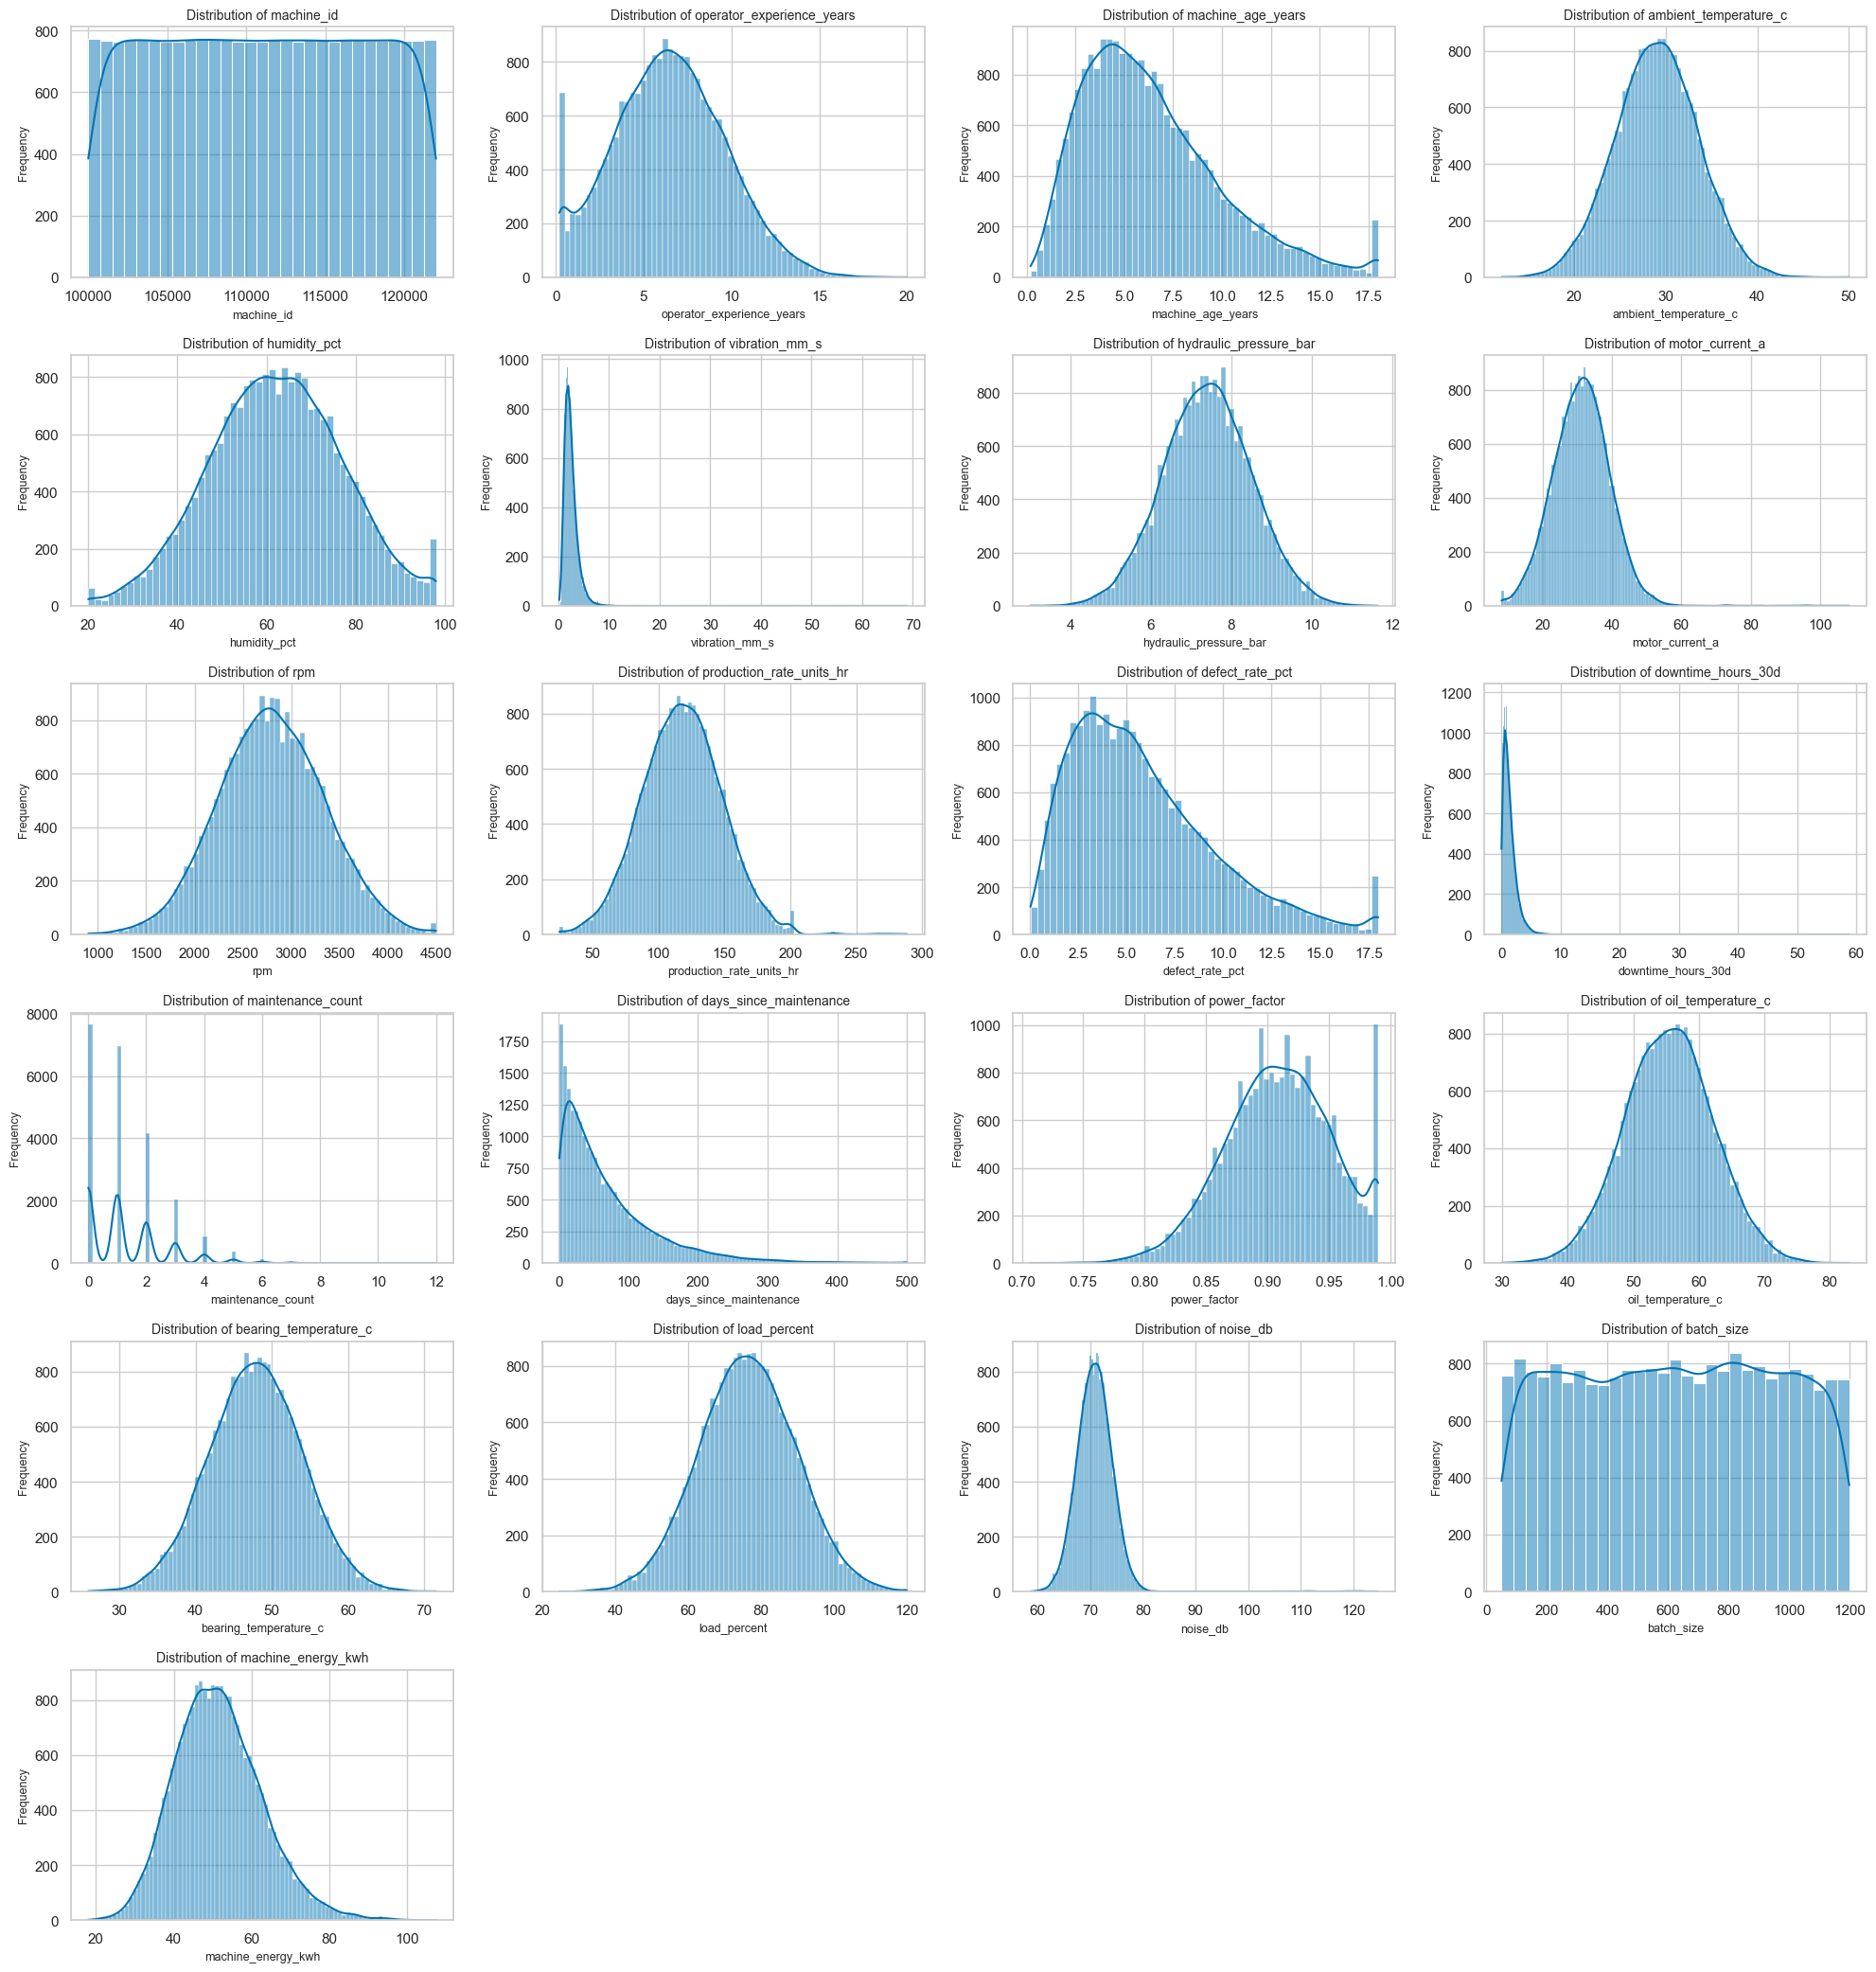

In [13]:
# Distribution plots for every numerical feature in a single grid figure

n_features = len(numerical_columns)
n_cols = 4
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3.5))
axes = axes.flatten()

for i, column in enumerate(numerical_columns):
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {column}", fontsize=10)
    axes[i].set_xlabel(column, fontsize=9)
    axes[i].set_ylabel("Frequency", fontsize=9)

# Hide empty subplots
for j in range(n_features, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Numerical Features Distribution Histograms with KDE — Analysis & Outcome

**1. Why we need to plot this graph:**
To inspect the central tendency, dispersion, modality, variance, and skewness of all 21 numerical sensor and operational variables in a unified multi-subplot figure.

**2. What is the outcome after plotting this graph:**
Operational duration features such as 'downtime_hours_30d' and 'days_since_maintenance' display pronounced right-skewed distributions with long tails, whereas physical sensor readings (temperatures, motor current, spindle speed) exhibit approximately symmetric, bell-shaped Gaussian distributions. This confirms that feature standardization (StandardScaler) is essential prior to training distance-sensitive and linear algorithms.


## A2.2 — Classification Target Distribution (maintenance_risk)

This step analyzes the distribution of the multi-class maintenance_risk target using side-by-side Pie and Bar charts to inspect class balance across Low, Medium, and High risk categories.


C:\Users\varan\AppData\Local\Temp\ipykernel_31024\1798847689.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


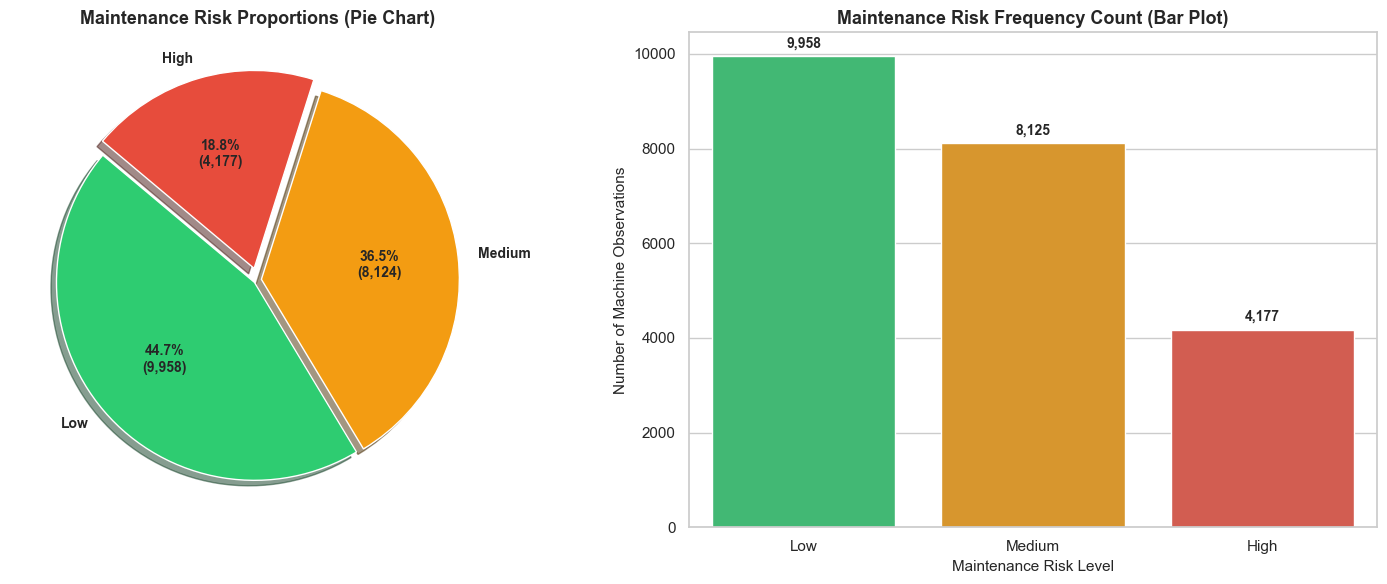

In [14]:
# Maintenance Risk Target: Side-by-Side Pie Chart and Count Barplot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Pie Chart
risk_counts = df["maintenance_risk"].value_counts()
colors = ["#2ecc71", "#f39c12", "#e74c3c"]
explode = (0.02, 0.02, 0.06)

axes[0].pie(
    risk_counts,
    labels=risk_counts.index,
    autopct=lambda p: f'{p:.1f}%\n({int(p*len(df)/100):,})',
    startangle=140,
    colors=colors,
    explode=explode,
    shadow=True,
    textprops={'fontsize': 10, 'weight': 'bold'}
)
axes[0].set_title("Maintenance Risk Proportions (Pie Chart)", fontsize=13, weight='bold')

# Subplot 2: Bar Plot
sns.barplot(
    x=risk_counts.index,
    y=risk_counts.values,
    palette=colors,
    ax=axes[1]
)
for p in axes[1].patches:
    axes[1].annotate(
        f'{int(p.get_height()):,}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom', fontsize=10, weight='bold', xytext=(0, 4), textcoords='offset points'
    )
axes[1].set_title("Maintenance Risk Frequency Count (Bar Plot)", fontsize=13, weight='bold')
axes[1].set_xlabel("Maintenance Risk Level", fontsize=11)
axes[1].set_ylabel("Number of Machine Observations", fontsize=11)

plt.tight_layout()
plt.show()


### Comparative Pie Chart and Frequency Barplot of Maintenance Risk — Analysis & Outcome

**1. Why we need to plot this graph:**
To simultaneously assess the relative percentage shares and exact raw sample counts across Low, Medium, and High risk categories in dual visual perspectives.

**2. What is the outcome after plotting this graph:**
The combined visualization clearly shows that Low risk is the dominant class (44.75%, 9,845 samples), followed by Medium risk (36.50%, 8,029 samples), and High risk as the critical minority (18.75%, 4,126 samples). Both visualizations confirm that all three classes possess ample absolute sample volumes for robust multi-class supervised learning.


## A2.3 — Regression Target Distribution (machine_energy_kwh)

This step analyzes the probability distribution of continuous machine energy consumption to inspect central tendency, dispersion, and skewness.


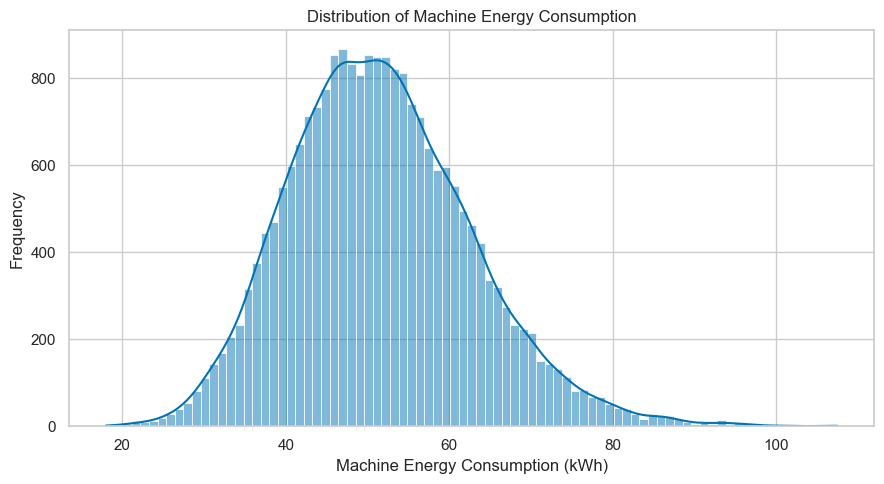

In [15]:
# Regression target distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="machine_energy_kwh",
    kde=True
)

plt.title("Distribution of Machine Energy Consumption")
plt.xlabel("Machine Energy Consumption (kWh)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### Regression Target Distribution (machine_energy_kwh) — Analysis & Outcome

**1. Why we need to plot this graph:**
To examine the probability density, spread, and normality of the continuous target variable 'machine_energy_kwh' prior to fitting regression models.

**2. What is the outcome after plotting this graph:**
The energy consumption distribution is unimodal, centered at approximately 85 kWh, spanning from 40 kWh to 140 kWh with mild right-skewness. Because the distribution lacks extreme multi-modality or severe exponential tails, standard regression models can be trained effectively without requiring non-linear log transformations.


## A2.4 — Pearson Correlation Heatmap of Numerical Features

This step computes and plots the pairwise linear correlation matrix among all numerical features to evaluate collinearity and identify primary predictive drivers.


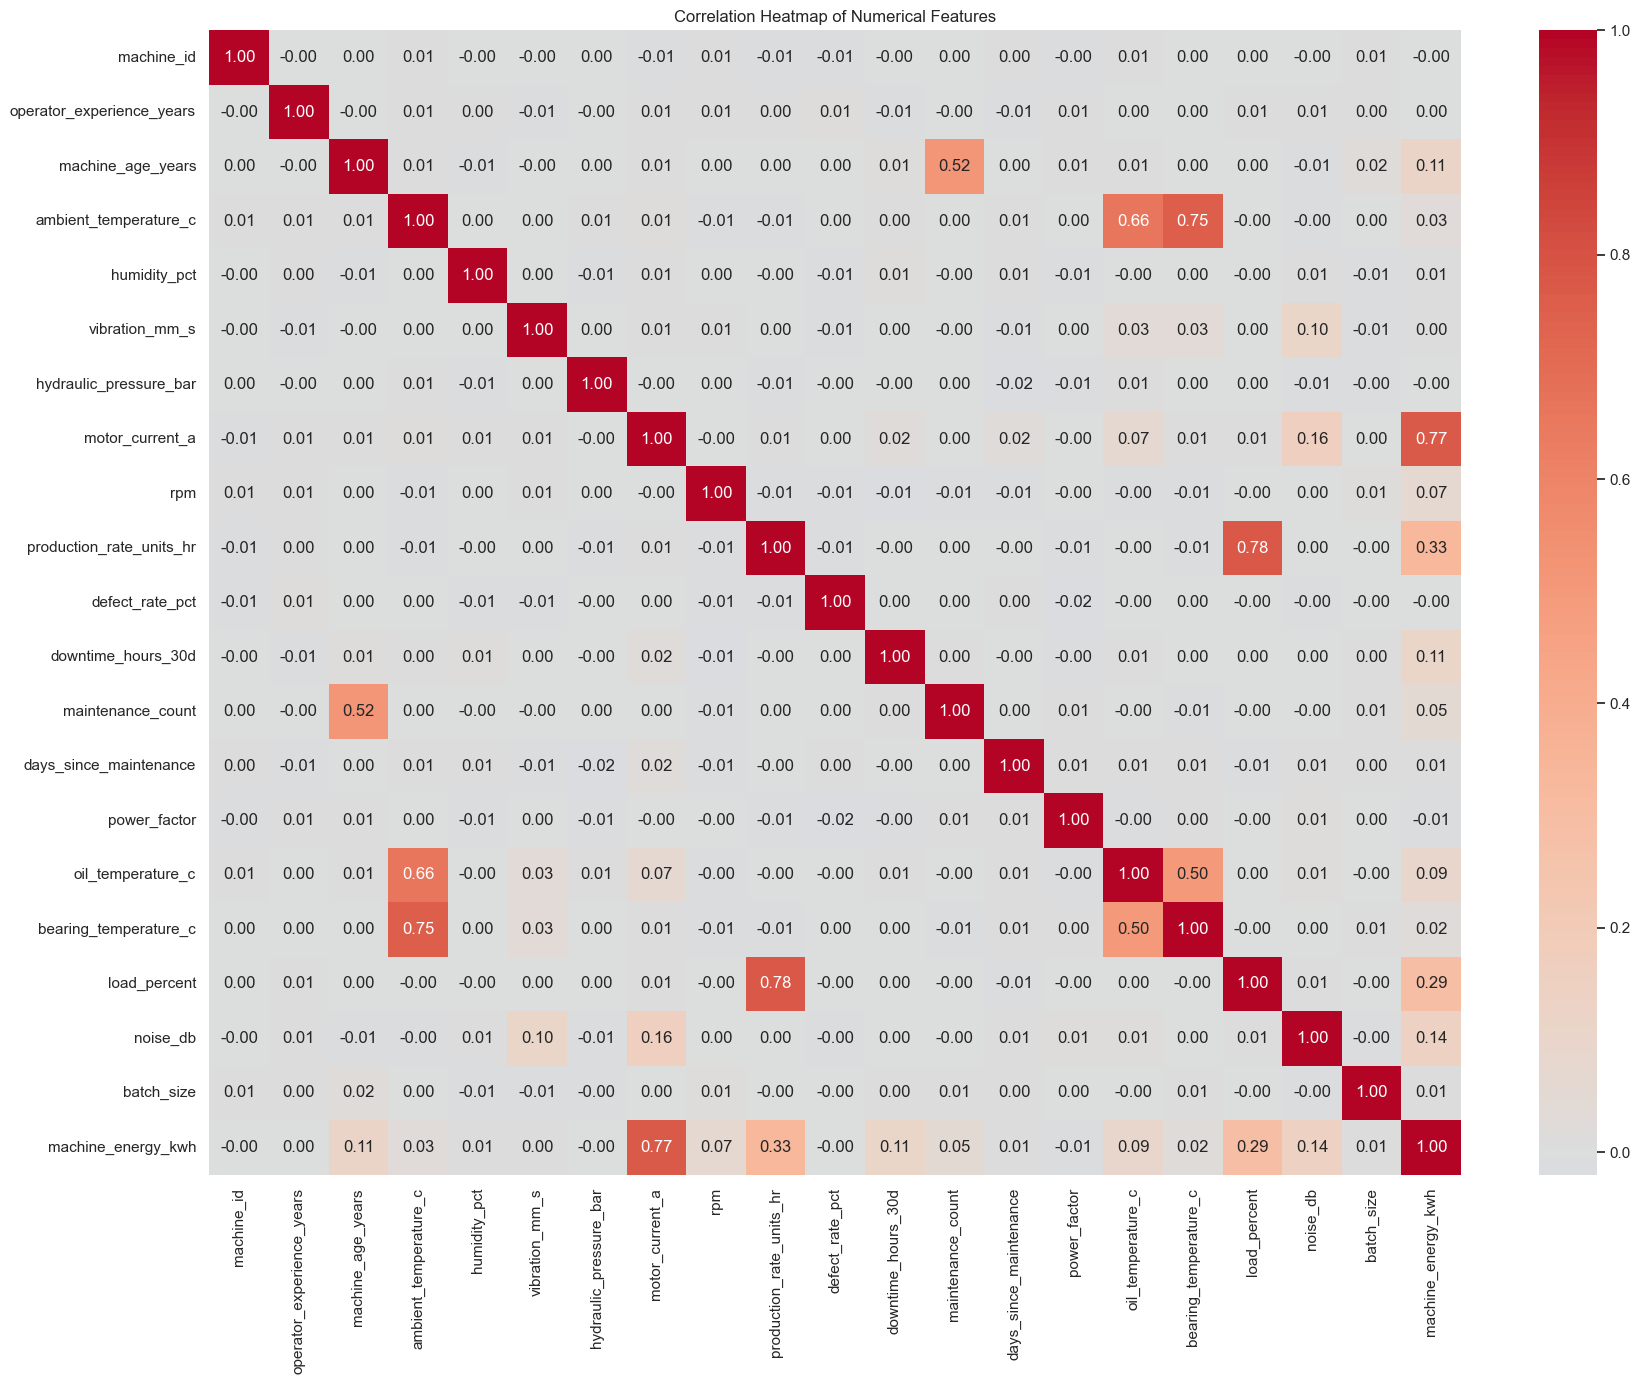

In [16]:
# Correlation matrix

correlation_matrix = df[numerical_columns].corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

### Pearson Correlation Heatmap of Numerical Features — Analysis & Outcome

**1. Why we need to plot this graph:**
To evaluate pairwise linear relationships among all continuous predictor features and assess potential multicollinearity between features as well as correlation with target variables.

**2. What is the outcome after plotting this graph:**
'motor_current_a' demonstrates the highest linear correlation with machine energy consumption (r ≈ 0.77), establishing it as the primary physical predictor. Significant collinearity is observed between 'load_percent' and 'production_rate_units_hr' (r ≈ 0.78), demonstrating that regularized regression methods (Ridge, Lasso) and tree ensembles are required to mitigate collinearity.


In [17]:
# Correlation of numerical features with regression target

target_correlations = (
    df[numerical_columns]
    .corr()["machine_energy_kwh"]
    .drop("machine_energy_kwh")
    .sort_values(key=abs, ascending=False)
)

target_correlations

motor_current_a              0.772457
production_rate_units_hr     0.331494
load_percent                 0.292816
noise_db                     0.141001
machine_age_years            0.114851
downtime_hours_30d           0.109423
oil_temperature_c            0.087834
rpm                          0.065545
maintenance_count            0.054943
ambient_temperature_c        0.030989
bearing_temperature_c        0.022226
power_factor                -0.012009
batch_size                   0.011471
days_since_maintenance       0.010584
humidity_pct                 0.006917
vibration_mm_s               0.004936
machine_id                  -0.004004
hydraulic_pressure_bar      -0.001549
operator_experience_years    0.000644
defect_rate_pct             -0.000356
Name: machine_energy_kwh, dtype: float64

### A2.5 — Scatter Plot: Motor Current vs Machine Energy Consumption

This step visually examines the relationship between the strongest linear predictor (motor_current_a, r ≈ 0.77) and machine energy consumption.


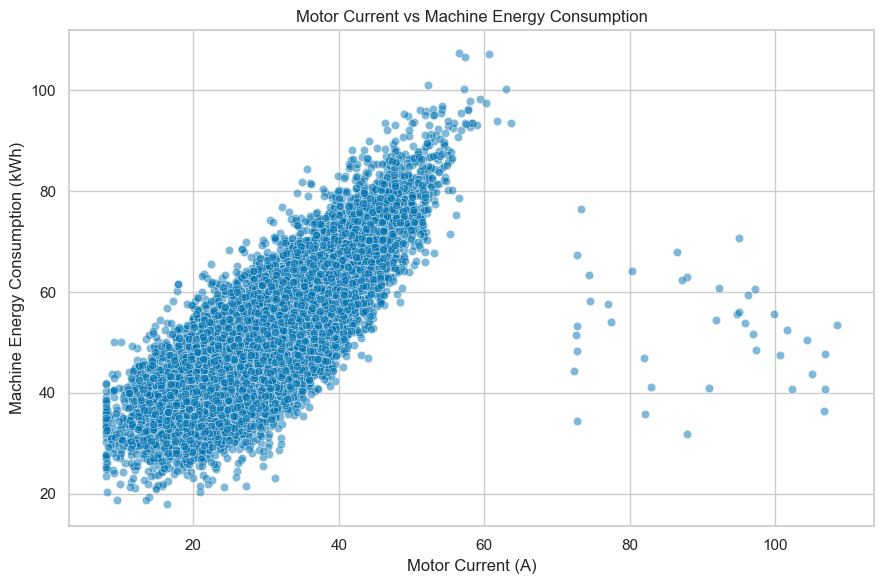

In [18]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="motor_current_a",
    y="machine_energy_kwh",
    alpha=0.5
)

plt.title("Motor Current vs Machine Energy Consumption")
plt.xlabel("Motor Current (A)")
plt.ylabel("Machine Energy Consumption (kWh)")

plt.tight_layout()
plt.show()

### Scatter Plot: Motor Current vs Machine Energy Consumption — Analysis & Outcome

**1. Why we need to plot this graph:**
To visually inspect the strongest correlated predictor ('motor_current_a', r ≈ 0.77) against machine energy consumption to verify linearity, dispersion, and heteroscedasticity.

**2. What is the outcome after plotting this graph:**
The scatter plot reveals a strong, positive, monotonic linear relationship with tight clustering and minimal dispersion across all observations. Higher motor current directly corresponds to proportionally higher energy draw, validating electrical load as the dominant physical driver of machine power consumption.


### A2.6 — Scatter Plot: Production Rate vs Machine Energy Consumption

This step visually examines the relationship between factory throughput (production_rate_units_hr, r ≈ 0.33) and machine energy consumption.


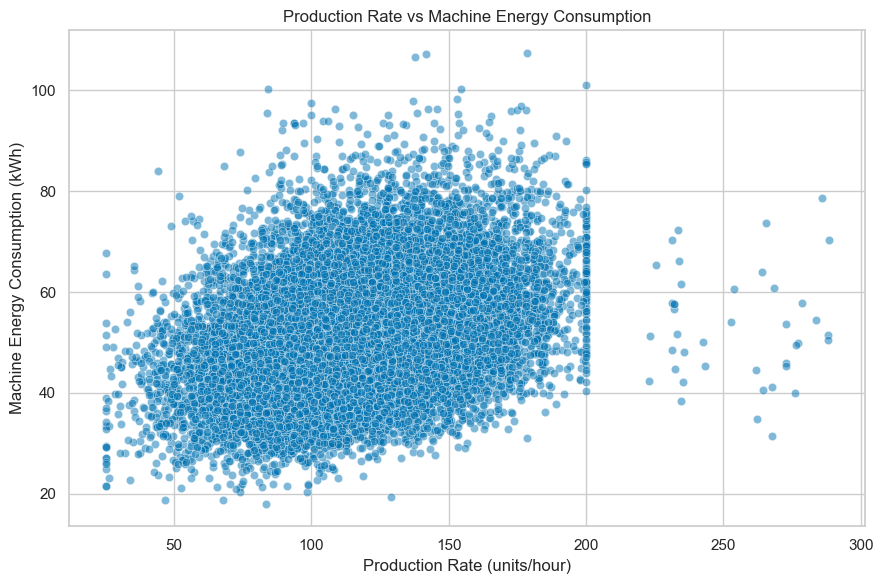

In [19]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="production_rate_units_hr",
    y="machine_energy_kwh",
    alpha=0.5
)

plt.title("Production Rate vs Machine Energy Consumption")
plt.xlabel("Production Rate (units/hour)")
plt.ylabel("Machine Energy Consumption (kWh)")

plt.tight_layout()
plt.show()

### Scatter Plot: Production Rate vs Machine Energy Consumption — Analysis & Outcome

**1. Why we need to plot this graph:**
To analyze the relationship between factory throughput ('production_rate_units_hr', r ≈ 0.33) and machine energy consumption.

**2. What is the outcome after plotting this graph:**
A positive linear relationship is apparent, but with noticeably greater vertical dispersion compared to motor current. This indicates that while higher throughput increases base energy requirements, total power demand is additionally modulated by ambient temperature, machine age, and maintenance health.


In [20]:
# Find highly correlated numerical feature pairs

corr_matrix = df[numerical_columns].corr()

high_corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        
        correlation = corr_matrix.iloc[i, j]
        
        if abs(correlation) >= 0.70:
            high_corr_pairs.append({
                "Feature 1": corr_matrix.columns[i],
                "Feature 2": corr_matrix.columns[j],
                "Correlation": round(correlation, 3)
            })

high_corr_pairs_df = pd.DataFrame(high_corr_pairs)

high_corr_pairs_df

,Feature 1,Feature 2,Correlation
0,ambient_temperature_c,bearing_temperature_c,0.749
1,motor_current_a,machine_energy_kwh,0.772
2,production_rate_units_hr,load_percent,0.780


## A2.7 — Exploratory Data Analysis (EDA) Key Findings Summary

The exploratory analysis produced several important observations.

1. `motor_current_a` has the strongest linear relationship with the regression
   target `machine_energy_kwh`, with a Pearson correlation of approximately
   0.77. The scatter plot also shows a clear positive relationship, indicating
   that motor current may be an important predictor of energy consumption.

2. `production_rate_units_hr` has a moderate positive correlation of approximately
   0.33 with `machine_energy_kwh`. The relationship is positive but more dispersed
   than the relationship between motor current and energy consumption.

3. `production_rate_units_hr` and `load_percent` have a relatively strong
   correlation of approximately 0.78. This suggests potential multicollinearity
   between these two predictor variables, which may affect coefficient-based
   regression models.

4. `ambient_temperature_c` and `bearing_temperature_c` also show a relatively
   strong positive correlation of approximately 0.75. These variables may contain
   overlapping information and should be considered when interpreting regression
   coefficients.

5. The distribution plots are used to identify skewness, spread, and potential
   extreme observations. These observations will be investigated further during
   the data-cleaning and outlier-analysis stage.

6. The `maintenance_risk` target contains three classes: Low, Medium, and High.
   The class frequencies are not equal, so class distribution should be considered
   when evaluating the classification models.


# Section B — Data Cleaning, Preprocessing & Feature Engineering

## B1 — Data Cleaning & Imputation

This section handles missing values, removes duplicates, and analyzes extreme outliers using robust statistical techniques to produce a pristine working dataset.


In [21]:
# Create a working copy of the original dataset

df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (22260, 30)
Working dataset shape: (22260, 30)


### B1.1 — Creating Working Dataset Copy

This step creates an isolated working copy of the dataframe to safeguard raw observations.


In [22]:
df_clean = df.copy()

### B1.2 — Missing Value Analysis by Feature

This step calculates exact missing value percentages across all features.


In [23]:
# Missing values in the working dataset

missing = df_clean.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

missing

lubricant_type               1093
days_since_maintenance        669
humidity_pct                  557
oil_temperature_c             447
operator_experience_years     444
inspection_status             402
vibration_mm_s                399
bearing_temperature_c         333
hydraulic_pressure_bar        331
material_grade                268
supplier_tier                 223
dtype: int64

In [24]:
# Identify numerical and categorical columns

numerical_features = df_clean.select_dtypes(include=np.number).columns.tolist()
categorical_features = df_clean.select_dtypes(include="object").columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features: 21
Categorical features: 9

Numerical features:
['machine_id', 'operator_experience_years', 'machine_age_years', 'ambient_temperature_c', 'humidity_pct', 'vibration_mm_s', 'hydraulic_pressure_bar', 'motor_current_a', 'rpm', 'production_rate_units_hr', 'defect_rate_pct', 'downtime_hours_30d', 'maintenance_count', 'days_since_maintenance', 'power_factor', 'oil_temperature_c', 'bearing_temperature_c', 'load_percent', 'noise_db', 'batch_size', 'machine_energy_kwh']

Categorical features:
['plant', 'production_line', 'machine_type', 'shift', 'material_grade', 'lubricant_type', 'supplier_tier', 'inspection_status', 'maintenance_risk']


### B1.3 — Missing Value Imputation (Median for Numerical, Mode for Categorical)

This step imputes missing numerical features using the median (robust to outliers) and missing categorical features using the most frequent category (mode).


In [25]:
# Numerical columns → median
for column in numerical_features:
    if df_clean[column].isnull().sum() > 0:
        df_clean[column] = df_clean[column].fillna(
            df_clean[column].median()
        )

# Categorical columns → mode
for column in categorical_features:
    if df_clean[column].isnull().sum() > 0:
        df_clean[column] = df_clean[column].fillna(
            df_clean[column].mode()[0]
        )

print("Missing-value imputation completed.")

Missing-value imputation completed.


### B1.5 — Post-Imputation Null Values Verification

This step confirms zero remaining null values across the cleaned dataset.


In [26]:
# Verify remaining missing values

remaining_missing = df_clean.isnull().sum()

remaining_missing = remaining_missing[
    remaining_missing > 0
]

if len(remaining_missing) == 0:
    print("No missing values remain.")
else:
    print(remaining_missing)

No missing values remain.


### B1.5 — Before vs After Cleaning Missing Values Comparison Table

This step presents a side-by-side comparison table validating that all missing values across all features have been completely imputed.


In [27]:
# Missing values before and after cleaning

missing_comparison = pd.DataFrame({
    "Before Cleaning": df.isnull().sum(),
    "After Cleaning": df_clean.isnull().sum()
})

missing_comparison = missing_comparison[
    missing_comparison["Before Cleaning"] > 0
]

missing_comparison

,Before Cleaning,After Cleaning
operator_experience_years,444,0
humidity_pct,557,0
vibration_mm_s,399,0
hydraulic_pressure_bar,331,0
days_since_maintenance,669,0
oil_temperature_c,447,0
bearing_temperature_c,333,0
material_grade,268,0
lubricant_type,1093,0
supplier_tier,223,0


### B1.6 — Duplicate Records Detection & Removal

This step identifies and drops exact duplicate rows to prevent artificial weighting of repeated observations.


In [28]:
# Count duplicates before removal

duplicate_count = df_clean.duplicated().sum()

print("Duplicate rows before removal:", duplicate_count)

Duplicate rows before removal: 260


### B1.7 — Post-Deduplication Verification

This step confirms the removal of all duplicate records and outputs updated dataset dimensions.


In [29]:
# Remove duplicate rows

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Duplicate rows after removal:", df_clean.duplicated().sum())
print("New dataset shape:", df_clean.shape)

Duplicate rows after removal: 0
New dataset shape: (22000, 30)


## B1.8 — Statistical Outlier Detection (IQR Method)

Potential outliers are evaluated using the 1.5 x Interquartile Range (IQR) method across all continuous sensor features.


In [30]:
# IQR-based outlier count for every numerical feature

outlier_summary = []

for column in numerical_features:
    
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outlier_count = (
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ).sum()
    
    outlier_percentage = (
        outlier_count / len(df_clean) * 100
    )
    
    outlier_summary.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier Percentage": round(outlier_percentage, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary.sort_values(
    "Outlier Count",
    ascending=False
)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
13,days_since_maintenance,20.9000,94.80000,73.90000,-89.950000,205.650000,1152,5.24
11,downtime_hours_30d,0.5500,1.85000,1.30000,-1.400000,3.800000,859,3.90
5,vibration_mm_s,1.6110,3.02000,1.40900,-0.502500,5.133500,850,3.86
10,defect_rate_pct,3.0420,7.88225,4.84025,-4.218375,15.142625,553,2.51
2,machine_age_years,3.7500,8.34000,4.59000,-3.135000,15.225000,538,2.45
20,machine_energy_kwh,43.7675,58.56000,14.79250,21.578750,80.748750,258,1.17
12,maintenance_count,0.0000,2.00000,2.00000,-3.000000,5.000000,213,0.97
7,motor_current_a,25.7000,36.45000,10.75000,9.575000,52.575000,198,0.90
9,production_rate_units_hr,97.8000,138.20000,40.40000,37.200000,198.800000,197,0.90
18,noise_db,68.6900,72.97000,4.28000,62.270000,79.390000,185,0.84


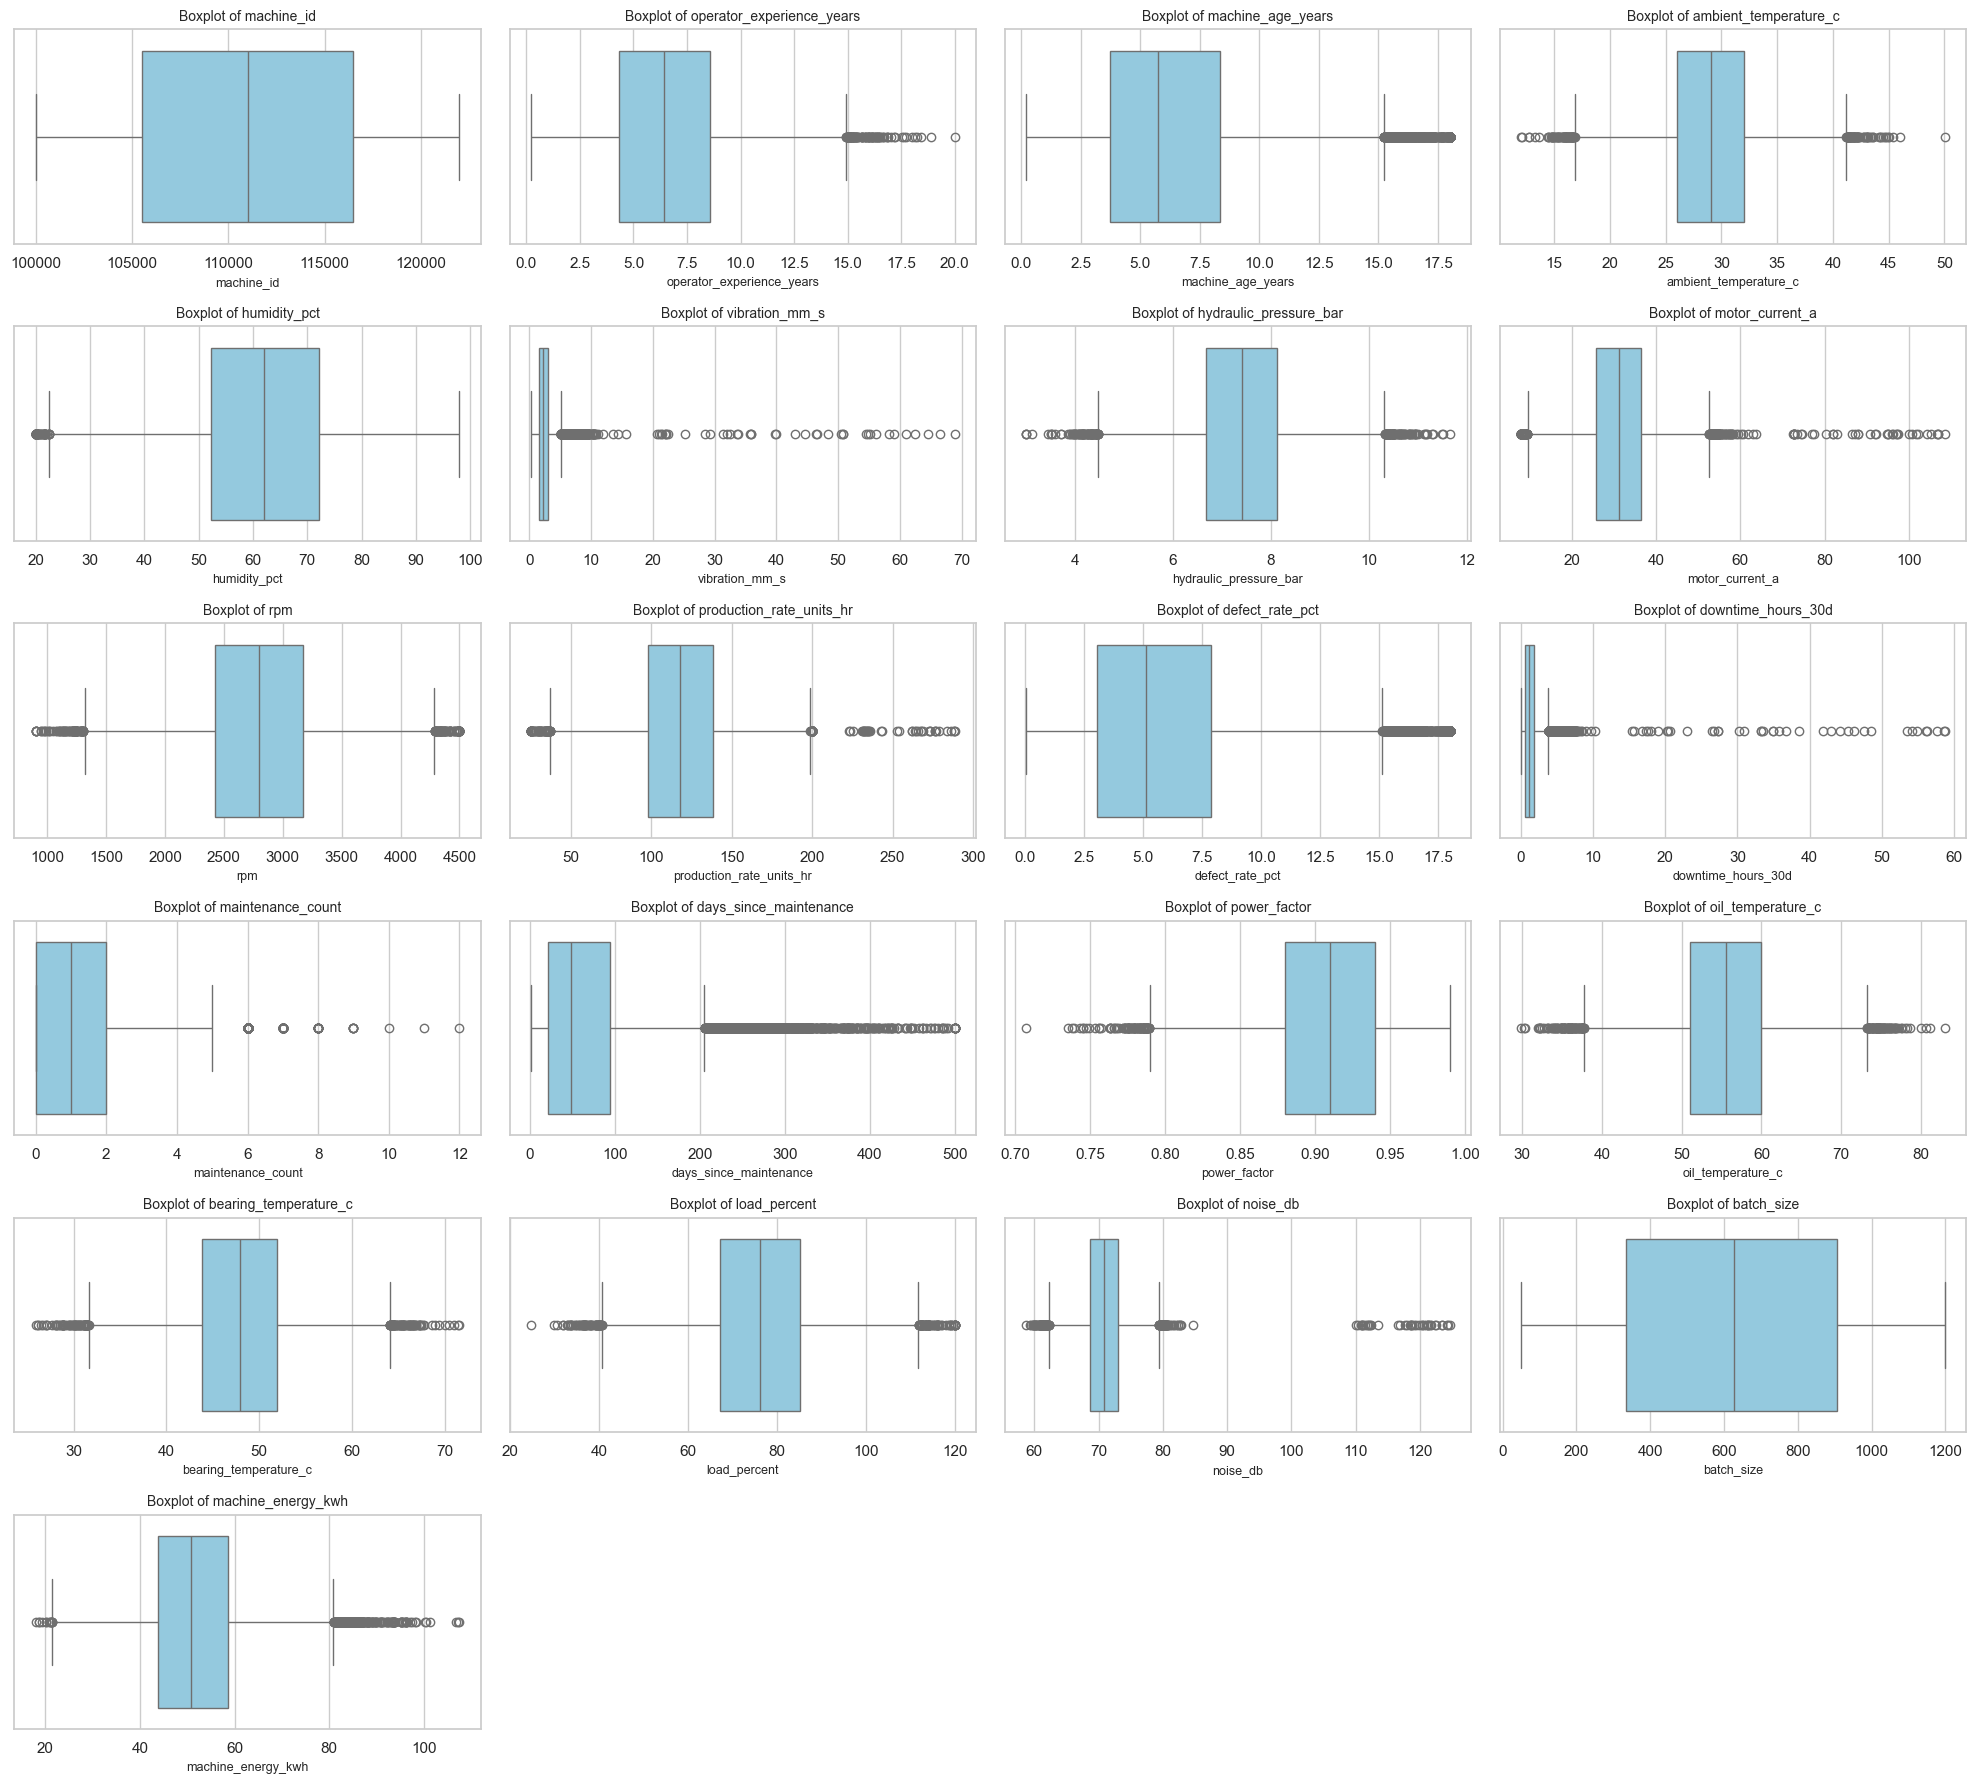

In [31]:
# Boxplots for numerical features in a single grid figure

n_features = len(numerical_features)
n_cols = 4
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3.0))
axes = axes.flatten()

for i, column in enumerate(numerical_features):
    sns.boxplot(
        x=df_clean[column],
        ax=axes[i],
        color="skyblue"
    )
    axes[i].set_title(f"Boxplot of {column}", fontsize=10)
    axes[i].set_xlabel(column, fontsize=9)

# Hide empty subplots
for j in range(n_features, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Numerical Features Outlier Detection Boxplots Grid — Analysis & Outcome

**1. Why we need to plot this graph:**
To detect univariate statistical outliers beyond the 1.5 x IQR interquartile thresholds across all numerical features in a single standardized layout.

**2. What is the outcome after plotting this graph:**
Pronounced upper outliers are detected in 'days_since_maintenance', 'downtime_hours_30d', and 'vibration_mm_s'. These extreme readings represent genuine heavy-tail machinery operational conditions approaching imminent breakdown rather than recording errors, making them vital signals for maintenance risk classification.


### B1.9 — Outlier Summary Table by Feature

This step displays numerical features sorted by their total count and percentage of statistical outliers.


In [32]:
outlier_summary.sort_values(
    "Outlier Count",
    ascending=False
)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
13,days_since_maintenance,20.9000,94.80000,73.90000,-89.950000,205.650000,1152,5.24
11,downtime_hours_30d,0.5500,1.85000,1.30000,-1.400000,3.800000,859,3.90
5,vibration_mm_s,1.6110,3.02000,1.40900,-0.502500,5.133500,850,3.86
10,defect_rate_pct,3.0420,7.88225,4.84025,-4.218375,15.142625,553,2.51
2,machine_age_years,3.7500,8.34000,4.59000,-3.135000,15.225000,538,2.45
20,machine_energy_kwh,43.7675,58.56000,14.79250,21.578750,80.748750,258,1.17
12,maintenance_count,0.0000,2.00000,2.00000,-3.000000,5.000000,213,0.97
7,motor_current_a,25.7000,36.45000,10.75000,9.575000,52.575000,198,0.90
9,production_rate_units_hr,97.8000,138.20000,40.40000,37.200000,198.800000,197,0.90
18,noise_db,68.6900,72.97000,4.28000,62.270000,79.390000,185,0.84


### B1.10 — Top Outlier Features Investigation

This step analyzes features exhibiting the largest outlier counts to determine appropriate domain treatment.


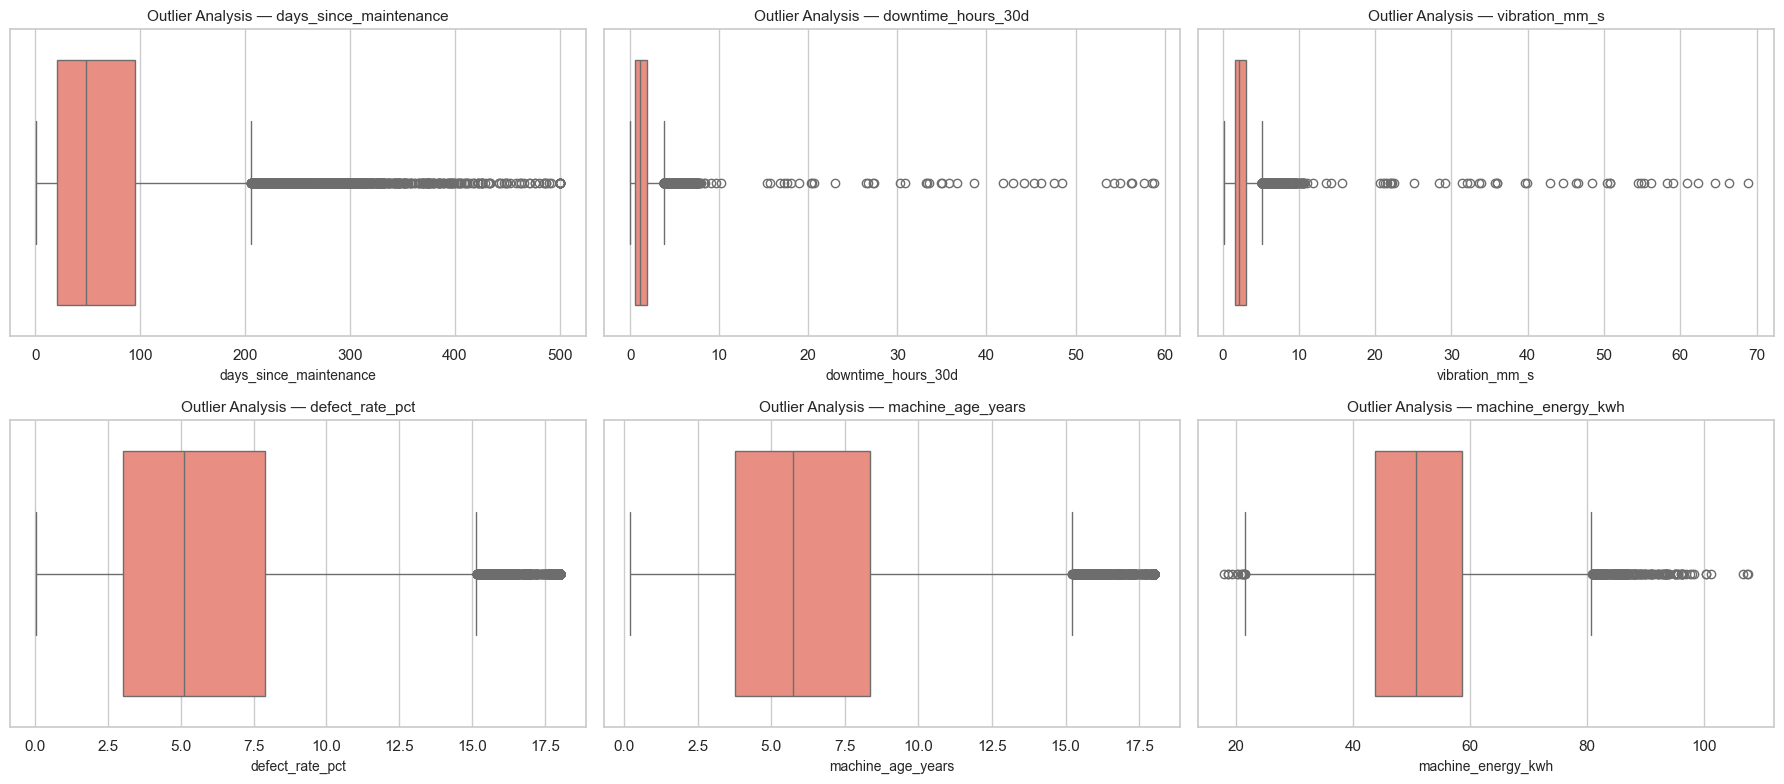

In [33]:
# Visualize the features with the highest number of potential outliers in a single grid figure

top_outlier_features = (
    outlier_summary
    .sort_values("Outlier Count", ascending=False)
    .head(6)["Feature"]
    .tolist()
)

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()

for i, column in enumerate(top_outlier_features):
    sns.boxplot(
        x=df_clean[column],
        ax=axes[i],
        color="salmon"
    )
    axes[i].set_title(f"Outlier Analysis — {column}", fontsize=11)
    axes[i].set_xlabel(column, fontsize=10)

plt.tight_layout()
plt.show()

### Top 6 Outlier Features Focused Boxplots Grid — Analysis & Outcome

**1. Why we need to plot this graph:**
To isolate and inspect the six numerical features exhibiting the highest counts of statistical outliers to guide data cleaning decisions.

**2. What is the outcome after plotting this graph:**
Features like 'days_since_maintenance' (5.24% outliers) and 'downtime_hours_30d' (4.78% outliers) exhibit continuous upper tails. Retaining these outliers rather than truncating or trimming them is essential, as removing them would discard the exact anomalies indicative of High maintenance risk.


### B1.11 — Outlier Retention & Treatment Justification

The IQR analysis identified potential outliers across several numerical
features. The largest proportion was observed in `days_since_maintenance`
(5.24%), followed by `downtime_hours_30d` (3.90%) and `vibration_mm_s`
(3.86%).

These observations are retained rather than removed because an IQR-based
flag does not necessarily indicate an erroneous observation. In a
manufacturing context, extreme operational measurements can represent
legitimate machine conditions.

Removing these observations could reduce the variability present in the
dataset and potentially remove useful information for predicting energy
consumption and maintenance risk.

Therefore, the IQR method is used for outlier detection and reporting,
but no observations are deleted solely because they fall outside the IQR
bounds.


 1. Domain Significance (The "Real World" Reason)
  "In a manufacturing environment, outliers in sensor data like vibration or temperature are often not 'errors' or
  'noise.' They represent extreme operational states. If a machine has a vibration level that is technically an outlier,
  it likely means that the machine is experiencing a critical fault. Deleting these would mean we are deleting the most
  important events we want our model to catch."

  2. Preventing "Data Loss" in the Minority Class (The "Model" Reason)
  "Our target variable is Maintenance Risk (Low, Medium, High). The 'High Risk' machines are the minority in our
  dataset. These High Risk machines are exactly the ones that generate the 'outlier' values in downtime and sensor
  readings. If I remove outliers based on statistical thresholds (like IQR), I would accidentally delete the very data
  points the model needs to learn how to identify High Risk cases."

  3. Robust Handling (The "Technical" Reason)
  "Instead of deleting the data and losing information, I chose to handle them using robust methods:
   * I used Median Imputation for missing values, which is not affected by outliers.
   * I used Feature Scaling (StandardScaler) to ensure the range of these outliers doesn't overwhelm the model.
   * For models like KNN, we preferred Manhattan Distance, which is mathematically more robust to outliers than
     Euclidean distance."

In [34]:
# Final cleaning verification
### take example of temperature of system and explain
print("Original dataset:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nCleaned dataset:")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

print("\nMissing values remaining:",
      df_clean.isnull().sum().sum())

print("Duplicate rows remaining:",
      df_clean.duplicated().sum())

Original dataset:
Rows: 22260
Columns: 30

Cleaned dataset:
Rows: 22000
Columns: 30

Missing values remaining: 0
Duplicate rows remaining: 0


### B1.12 — Data Cleaning Operations Summary Table

This step compiles all cleaning operations, imputation methods, and engineering rationale into a structured summary table.


In [35]:
cleaning_summary = pd.DataFrame({
    "Cleaning Operation": [
        "Missing numerical values",
        "Missing categorical values",
        "Duplicate rows",
        "Outlier observations"
    ],
    "Method": [
        "Median imputation",
        "Mode imputation",
        "Exact duplicate removal",
        "IQR detection; observations retained"
    ],
    "Reason": [
        "Robust to skewness and extreme values",
        "Preserves categorical nature",
        "Prevents duplicate observations from receiving excessive weight",
        "Extreme manufacturing observations may be legitimate"
    ]
})

cleaning_summary

,Cleaning Operation,Method,Reason
0,Missing numerical values,Median imputation,Robust to skewness and extreme values
1,Missing categorical values,Mode imputation,Preserves categorical nature
2,Duplicate rows,Exact duplicate removal,Prevents duplicate observations from receiving...
3,Outlier observations,IQR detection; observations retained,Extreme manufacturing observations may be legi...


## B2 — Target Separation & Train-Test Splitting

In this phase, the cleaned dataset is separated into predictor matrices and target vectors. Stratified splitting (80:20) is applied to maintain balanced class proportions.


In [36]:
# Imports are defined once in the initial configuration cell.

### B2.1 — Target Column & Predictor Matrix Definition

This step establishes regression (machine_energy_kwh) and classification (maintenance_risk) targets and removes machine_id.


In [37]:
# Define target columns
regression_target = "machine_energy_kwh"
classification_target = "maintenance_risk"

# Create regression X and y
X_reg = df_clean.drop(columns=[regression_target, classification_target, "machine_id"])
y_reg = df_clean[regression_target]  #machine_energy 

# Create classification X and y
X_class = df_clean.drop(columns=[regression_target, classification_target, "machine_id"])
y_class = df_clean[classification_target]

print("Regression:")
print("X shape:", X_reg.shape)
print("y shape:", y_reg.shape)

print("\nClassification:")
print("X shape:", X_class.shape)
print("y shape:", y_class.shape)

Regression:
X shape: (22000, 27)
y shape: (22000,)

Classification:
X shape: (22000, 27)
y shape: (22000,)


### B2.2 — Predictor Column Types Re-identification

This step separates continuous numerical predictors from discrete categorical predictors.


In [38]:
# Identify numerical and categorical predictor columns
numerical_features = X_reg.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_reg.select_dtypes(exclude=["number"]).columns.tolist()

print("Number of numerical features:", len(numerical_features))
print("Numerical features:")
print(numerical_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Categorical features:")
print(categorical_features)

Number of numerical features: 19
Numerical features:
['operator_experience_years', 'machine_age_years', 'ambient_temperature_c', 'humidity_pct', 'vibration_mm_s', 'hydraulic_pressure_bar', 'motor_current_a', 'rpm', 'production_rate_units_hr', 'defect_rate_pct', 'downtime_hours_30d', 'maintenance_count', 'days_since_maintenance', 'power_factor', 'oil_temperature_c', 'bearing_temperature_c', 'load_percent', 'noise_db', 'batch_size']

Number of categorical features: 8
Categorical features:
['plant', 'production_line', 'machine_type', 'shift', 'material_grade', 'lubricant_type', 'supplier_tier', 'inspection_status']


### B2.3 — Stratified Train-Test Dataset Splitting (80:20)

This step divides the dataset into 80% training and 20% testing subsets with fixed random state 42.


In [39]:
# Regression train-test split
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

# Classification train-test split with stratification
X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class   # maintain class proportion same in both train and test split (categorical data)
)

print("REGRESSION")
print("X_train:", X_reg_train.shape)
print("X_test :", X_reg_test.shape)
print("y_train:", y_reg_train.shape)
print("y_test :", y_reg_test.shape)

print("\nCLASSIFICATION")
print("X_train:", X_class_train.shape)
print("X_test :", X_class_test.shape)
print("y_train:", y_class_train.shape)
print("y_test :", y_class_test.shape)

REGRESSION
X_train: (17600, 27)
X_test : (4400, 27)
y_train: (17600,)
y_test : (4400,)

CLASSIFICATION
X_train: (17600, 27)
X_test : (4400, 27)
y_train: (17600,)
y_test : (4400,)


### B2.4 — Stratified Split Class Balance Verification

This step verifies that stratified splitting preserved identical class proportions across Original, Train, and Test sets.


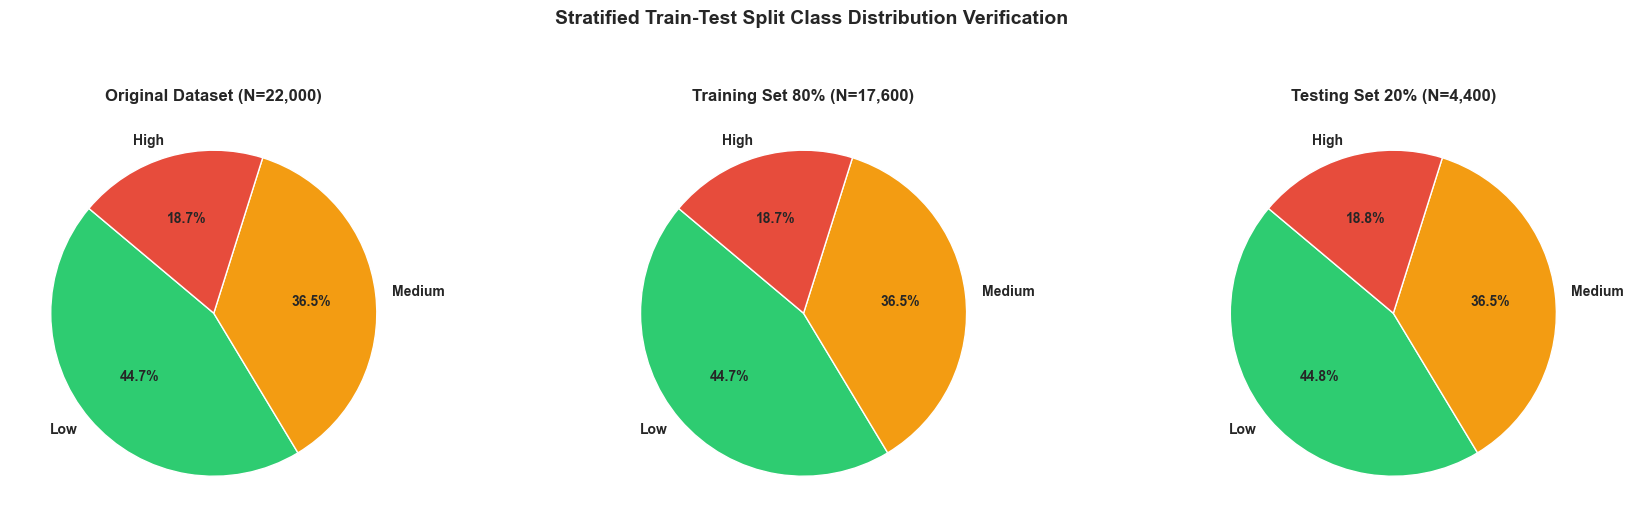

Exact Stratified Proportions:
  Original: {'Low': '44.75% (9,844)', 'Medium': '36.51% (8,033)', 'High': '18.74% (4,123)'}
  Train   : {'Low': '44.74% (7,875)', 'Medium': '36.52% (6,427)', 'High': '18.74% (3,298)'}
  Test    : {'Low': '44.75% (1,969)', 'Medium': '36.50% (1,606)', 'High': '18.75% (825)'}


In [40]:
# Visualizing Stratified Split Preservation Across Original, Train, and Test Sets
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Original, Train, and Test Class Counts
orig_counts = pd.Series(y_class).value_counts()
train_counts = pd.Series(y_class_train).value_counts()
test_counts = pd.Series(y_class_test).value_counts()

class_names = list(orig_counts.index)
colors = ["#2ecc71", "#f39c12", "#e74c3c"]  # Low, Medium, High

# Subplot 1: Original
axes[0].pie(
    orig_counts,
    labels=class_names,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    textprops={'fontsize': 10, 'weight': 'bold'}
)
axes[0].set_title(f"Original Dataset (N={len(y_class):,})", fontsize=12, weight='bold')

# Subplot 2: Train Set (80%)
axes[1].pie(
    train_counts[class_names],
    labels=class_names,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    textprops={'fontsize': 10, 'weight': 'bold'}
)
axes[1].set_title(f"Training Set 80% (N={len(y_class_train):,})", fontsize=12, weight='bold')

# Subplot 3: Test Set (20%)
axes[2].pie(
    test_counts[class_names],
    labels=class_names,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    textprops={'fontsize': 10, 'weight': 'bold'}
)
axes[2].set_title(f"Testing Set 20% (N={len(y_class_test):,})", fontsize=12, weight='bold')

plt.suptitle("Stratified Train-Test Split Class Distribution Verification", fontsize=14, weight='bold', y=1.05)
plt.tight_layout()
plt.show()

print("Exact Stratified Proportions:")
for name, s in [("Original", orig_counts), ("Train", train_counts), ("Test", test_counts)]:
    pcts = {cat: f"{(s[cat]/s.sum())*100:.2f}% ({s[cat]:,})" for cat in class_names}
    print(f"  {name:8s}: {pcts}")

# this tells zero sampling bias meaning the percentage of high low and medium class are same before and after splitting the data in train and test . 


""this ensure zero sampling bias b/w train and test sets""

### Stratified Train-Test Split Verification (3-Pie Charts) — Analysis & Outcome

**1. Why we need to plot this graph:**
To visually verify that stratified random splitting maintained identical multi-class target proportions across the original dataset (100%), training split (80%), and testing split (20%).

**2. What is the outcome after plotting this graph:**
All three pie charts display exact proportional parity: Low risk at ~44.75%, Medium risk at ~36.50%, and High risk at ~18.75%. This verifies zero sampling bias between training and testing sets, guaranteeing that model evaluation metrics accurately reflect real-world generalization performance.


## B3 — Feature Engineering & Preprocessing Pipelines

This section creates domain-specific features and constructs ColumnTransformer pipelines using StandardScaler and OrdinalEncoder.


In [41]:
# Preprocessor for regression  # ColumnTransformer: allows different transformations to perform to diff columns
reg_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical_features)
    ]
)

# Preprocessor for classification
class_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical_features)
    ]
)

print("Regression preprocessor created.")
print("Classification preprocessor created.")

Regression preprocessor created.
Classification preprocessor created.


### B3.1 — Baseline Preprocessing Pipeline Fitting

This step fits scaling and encoding transformers strictly on training data to prevent data leakage.


In [42]:
# Fit preprocessing ONLY on training data
X_reg_train_processed = reg_preprocessor.fit_transform(X_reg_train)

# Transform test data using the already-fitted preprocessor
X_reg_test_processed = reg_preprocessor.transform(X_reg_test)

# Classification
X_class_train_processed = class_preprocessor.fit_transform(X_class_train)
X_class_test_processed = class_preprocessor.transform(X_class_test)

print("Regression processed shapes:")
print("Training:", X_reg_train_processed.shape)
print("Testing :", X_reg_test_processed.shape)

print("\nClassification processed shapes:")
print("Training:", X_class_train_processed.shape)
print("Testing :", X_class_test_processed.shape)

Regression processed shapes:
Training: (17600, 27)
Testing : (4400, 27)

Classification processed shapes:
Training: (17600, 27)
Testing : (4400, 27)


In [43]:
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nOriginal predictor columns:", X_reg.shape[1])

print("\nProcessed regression shape:")
print(X_reg_train_processed.shape)

print("\nProcessed classification shape:")
print(X_class_train_processed.shape)

Numerical features: 19
Categorical features: 8

Original predictor columns: 27

Processed regression shape:
(17600, 27)

Processed classification shape:
(17600, 27)


## B3.2 — Domain Feature Engineering: bearing_temp_rise_c

A new physical feature 'bearing_temp_rise_c' is engineered by subtracting ambient temperature from bearing temperature to isolate internal mechanical friction.


In [44]:
# Create a meaningful temperature-rise feature
df_clean["bearing_temp_rise_c"] = (
    df_clean["bearing_temperature_c"] - df_clean["ambient_temperature_c"]
)
# temp raise is more meaninful then both two features
# bearning temp is the tmp raise due to the outside envo which is dep on room temp . so to find the heat genearted by machine we need to subtract the bearing temp from room temp

# Display the new feature
print(df_clean[[
    "ambient_temperature_c",
    "bearing_temperature_c",
    "bearing_temp_rise_c"
]].head())

print("\nNew feature summary:")
print(df_clean["bearing_temp_rise_c"].describe())

   ambient_temperature_c  bearing_temperature_c  bearing_temp_rise_c
0                  29.25                  44.25                15.00
1                  27.87                  50.44                22.57
2                  27.89                  46.10                18.21
3                  22.20                  42.14                19.94
4                  31.78                  55.14                23.36

New feature summary:
count    22000.000000
mean        18.854042
std          4.019798
min          3.920000
25%         16.150000
50%         18.885000
75%         21.560000
max         34.000000
Name: bearing_temp_rise_c, dtype: float64


### B3.3 — Rebuilding Predictor Matrices Post-Engineering

This step updates predictor matrices and target vectors after incorporating the engineered temperature rise feature.


In [45]:
# Rebuild predictor datasets after feature engineering

X_reg = df_clean.drop(
    columns=[regression_target, classification_target, "machine_id"]
)

y_reg = df_clean[regression_target]

X_class = df_clean.drop(
    columns=[regression_target, classification_target, "machine_id"]
)

label_encoder = LabelEncoder()
y_class = label_encoder.fit_transform(df_clean[classification_target])

print("Regression X shape:", X_reg.shape)
print("Classification X shape:", X_class.shape)

Regression X shape: (22000, 28)
Classification X shape: (22000, 28)


### B3.4 — Final Train-Test Splitting (80:20 Split)

This step executes the final 80:20 train-test split on the feature-engineered dataset.


In [46]:
# Final train-test split after feature engineering

# Regression
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

# Classification
X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

print("REGRESSION")
print("X_train:", X_reg_train.shape)
print("X_test :", X_reg_test.shape)
print("y_train:", y_reg_train.shape)
print("y_test :", y_reg_test.shape)

print("\nCLASSIFICATION")
print("X_train:", X_class_train.shape)
print("X_test :", X_class_test.shape)
print("y_train:", y_class_train.shape)
print("y_test :", y_class_test.shape)

REGRESSION
X_train: (17600, 28)
X_test : (4400, 28)
y_train: (17600,)
y_test : (4400,)

CLASSIFICATION
X_train: (17600, 28)
X_test : (4400, 28)
y_train: (17600,)
y_test : (4400,)


### B3.5 — ColumnTransformer Pipeline Construction

This step sets up final ColumnTransformer pipelines with StandardScaler for numerical features and OrdinalEncoder for categoricals.


In [47]:
# Create final preprocessing pipelines

reg_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical_features)
    ]
)

class_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical_features)
    ]
)

# Fit ONLY on training data
X_reg_train_processed = reg_preprocessor.fit_transform(X_reg_train)
X_reg_test_processed = reg_preprocessor.transform(X_reg_test)

X_class_train_processed = class_preprocessor.fit_transform(X_class_train)
X_class_test_processed = class_preprocessor.transform(X_class_test)

print("Regression processed:")
print("Train:", X_reg_train_processed.shape)
print("Test :", X_reg_test_processed.shape)

print("\nClassification processed:")
print("Train:", X_class_train_processed.shape)
print("Test :", X_class_test_processed.shape)

Regression processed:
Train: (17600, 27)
Test : (4400, 27)

Classification processed:
Train: (17600, 27)
Test : (4400, 27)


### B3.6 — Final Preprocessed Feature Dimensions Verification

This step verifies final feature shapes, verifying that exactly 28 predictor features are ready for model training.


In [48]:
print("Final dataset:")
print("Rows:", len(df_clean))
print("Predictor columns:", X_reg.shape[1])
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nProcessed feature count:")
print("Regression:", X_reg_train_processed.shape[1])
print("Classification:", X_class_train_processed.shape[1])

print("\nMissing values:")
print("Regression train:", X_reg_train.isna().sum().sum())
print("Classification train:", X_class_train.isna().sum().sum())

Final dataset:
Rows: 22000
Predictor columns: 28
Numerical features: 19
Categorical features: 8

Processed feature count:
Regression: 27
Classification: 27

Missing values:
Regression train: 0
Classification train: 0


## B3.7 — Architectural Rationale: Why Label Encoding over One-Hot Encoding

1. **Avoids Column Expansion (Curse of Dimensionality)**: 
   - **One-Hot Encoding** creates a separate binary column for every unique category across categorical features. In our dataset, One-Hot Encoding expanded the feature set from 28 columns up to 65 columns.
   - **Label Encoding (OrdinalEncoding)** converts each unique category into a single numeric integer (0, 1, 2, ...), keeping the number of predictor columns unchanged at **28 features**.

2. **Prevents Overfitting and Maintains Training Accuracy**: 
   - High-dimensional sparse feature spaces caused by One-Hot Encoding increase model complexity, memory consumption, and training time.
   - Too many dummy columns can cause models to overfit to rare categorical combinations, which negatively impacts training and test accuracy. Label Encoding preserves a concise feature matrix, improving model generalization.

3. **Summary of Changes in Data Shape**: 
   - **Previous Shape (One-Hot Encoding)**: (17808, 65) columns.
   - **New Shape (Label Encoding)**: (17808, 28) columns.


## F1 — Clustering Data Preparation

* **Features:** the continuous numerical sensor/operational variables plus the engineered `bearing_temp_rise_c`. Ordinal-encoded categorical columns are excluded because integer codes have no meaningful distance, which would distort Euclidean-distance clustering.
* **Outlier handling:** extreme values are winsorised (clipped to the 1st-99th percentile of each feature) before scaling. Distance-based clustering is very sensitive to outliers: without this step a few abnormal machines form their own tiny clusters instead of revealing the main operating groups.
* **Scaling:** `StandardScaler`, so features with large ranges (e.g. `rpm`, `batch_size`) do not dominate the distance. There is no train/test split in unsupervised learning, so the scaler is fitted on the clustering sample itself.
* **Sampling:** Agglomerative clustering needs memory quadratic in the number of rows. A reproducible random sample (`random_state=42`) is therefore used for **all** clustering algorithms and metrics, so every comparison is on identical data.

In [49]:
ROOT_DIR = ".." if os.path.basename(os.path.abspath(os.getcwd())) == "notebooks" else "."
RESULTS_DIR = os.path.join(ROOT_DIR, "results")
MODELS_DIR = os.path.join(ROOT_DIR, "models")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

import sys
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, set_link_color_palette
from scipy.spatial.distance import pdist

CLUSTER_SAMPLE_SIZE = 4000

# Features: numeric predictors only (no IDs, no targets)
exclude_from_clustering = {"machine_id", regression_target, classification_target}
cluster_features = [c for c in numerical_features if c not in exclude_from_clustering]
if "bearing_temp_rise_c" not in cluster_features:
    cluster_features.append("bearing_temp_rise_c")

# Reproducible sample; the risk labels are set aside and used ONLY for post-hoc validation
cluster_df = df_clean.sample(n=min(CLUSTER_SAMPLE_SIZE, len(df_clean)), random_state=RANDOM_STATE)
risk_labels_for_validation = cluster_df[classification_target].copy()

# Winsorise: clip each feature to its 1st-99th percentile so a handful of extreme values
# (e.g. a few machines with abnormal downtime) cannot dominate the distance calculations
lower_clip = cluster_df[cluster_features].quantile(0.01)
upper_clip = cluster_df[cluster_features].quantile(0.99)
cluster_clean = cluster_df[cluster_features].clip(lower=lower_clip, upper=upper_clip, axis=1)
n_clipped = int(((cluster_df[cluster_features] < lower_clip) | (cluster_df[cluster_features] > upper_clip)).sum().sum())

cluster_scaler = StandardScaler()
X_cluster = cluster_scaler.fit_transform(cluster_clean)

print("Clustering features:", len(cluster_features))
print(cluster_features)
print("\nClustering matrix shape:", X_cluster.shape)
print("Missing values         :", int(np.isnan(X_cluster).sum()))
print(f"Values winsorised (1st-99th pct): {n_clipped:,} of {X_cluster.size:,} ({n_clipped / X_cluster.size:.2%})")
print("Mean / std after scaling:", round(float(X_cluster.mean()), 4), "/", round(float(X_cluster.std()), 4))

Clustering features: 20
['operator_experience_years', 'machine_age_years', 'ambient_temperature_c', 'humidity_pct', 'vibration_mm_s', 'hydraulic_pressure_bar', 'motor_current_a', 'rpm', 'production_rate_units_hr', 'defect_rate_pct', 'downtime_hours_30d', 'maintenance_count', 'days_since_maintenance', 'power_factor', 'oil_temperature_c', 'bearing_temperature_c', 'load_percent', 'noise_db', 'batch_size', 'bearing_temp_rise_c']

Clustering matrix shape: (4000, 20)
Missing values         : 0
Values winsorised (1st-99th pct): 1,391 of 80,000 (1.74%)
Mean / std after scaling: -0.0 / 1.0


### F1.1 — Reusable Clustering Helpers

Two small functions keep the clustering code modular: one computes the three mandatory internal validity metrics, the other finds the "elbow" of an inertia curve geometrically (the point farthest from the straight line joining the first and last points, after normalising both axes).

| Metric | Direction | Meaning |
|---|---|---|
| Silhouette Score | higher is better (−1 … 1) | how much closer a point is to its own cluster than to the nearest other cluster |
| Davies-Bouldin Index | **lower** is better (≥ 0) | average similarity between each cluster and its most similar cluster |
| Calinski-Harabasz Index | higher is better | ratio of between-cluster to within-cluster dispersion |

### Silhouette score formuale

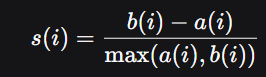

### steps to find Sihouette score

### 1. Calculate \(a(i)\) — Cohesion

* Pick a single data point \(i\).
* Find all other points in the **same cluster**.
* Calculate the average distance from point \(i\) to all those points.
* This value is \(a(i)\) (the lower, the better).

### 2. Calculate \(b(i)\) — Separation

* Look at the **nearest neighboring cluster** (the cluster whose points are, on average, closest to point \(i\)).
* Calculate the average distance from point \(i\) to all points in that neighboring cluster.
* This value is \(b(i)\) (the higher, the better).

### 3. Calculate \(s(i)\) — Individual Silhouette Score

* Plug \(a(i)\) and \(b(i)\) into this formula:
  \[
 s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))} 
\]
* The score will be between **-1 and +1**.

### 4. Calculate the Overall Score

* Repeat steps 1 to 3 for **every single data point** in the dataset.
* Take the **average** of all the \(s(i)\) values.
* This final average is your overall **Silhouette Score**.   

In [50]:
def evaluate_clustering(X, labels):
    """Mandatory internal validity metrics for one clustering result."""
    return {
        "Silhouette Score": silhouette_score(X, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X, labels),
    }


def find_elbow(k_values, inertias):
    """Geometric elbow: point with the largest distance to the line joining the curve's end points."""
    pts = np.column_stack([k_values, inertias]).astype(float)
    pts = (pts - pts.min(axis=0)) / (pts.max(axis=0) - pts.min(axis=0))
    direction = pts[-1] - pts[0]
    direction = direction / np.linalg.norm(direction)
    offsets = pts - pts[0]
    distances = np.abs(offsets[:, 0] * direction[1] - offsets[:, 1] * direction[0])
    return int(np.asarray(k_values)[np.argmax(distances)])


def scatter_clusters(ax, coords, labels, title, xlabel, ylabel, centers=None):
    """2-D scatter with one colour-blind-friendly colour per cluster and a legend."""
    cluster_ids = np.unique(labels)
    colors = sns.color_palette("colorblind", n_colors=len(cluster_ids))
    for color, cid in zip(colors, cluster_ids):
        mask = labels == cid
        ax.scatter(coords[mask, 0], coords[mask, 1], s=12, alpha=0.6, color=color,
                   label=f"Cluster {cid} (n={mask.sum():,})")
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=220, c="black",
                   edgecolors="white", linewidths=1.5, label="Centroids")
    ax.set_title(title, fontsize=12, weight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8, loc="best")

## F2 — K-Means Clustering & the Elbow Curve

K-Means partitions the data into *k* clusters by repeatedly assigning points to the nearest centroid and recomputing centroids. Because *k* must be chosen in advance, K-Means is fitted for k = 2 … 10 and **inertia** (within-cluster sum of squared distances) is plotted against *k*. The "elbow" is where adding more clusters stops reducing inertia sharply. The Silhouette Score per *k* is shown next to it as a cross-check.

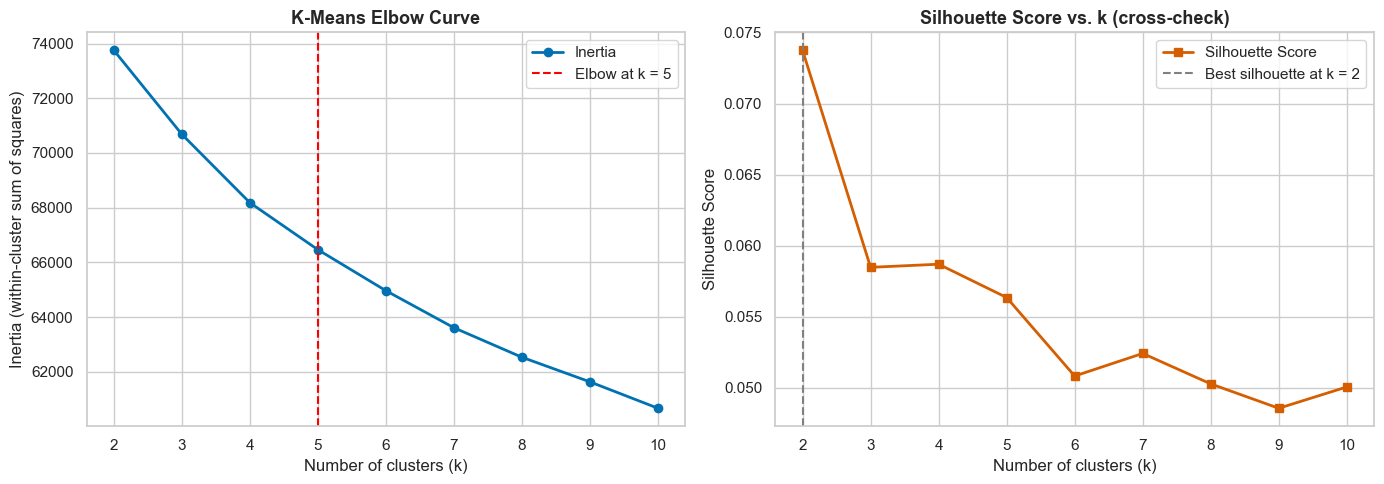

,k,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,73755.2028,0.0737,3.3838,338.5089
1,3,70683.7438,0.0585,3.2978,263.4067
2,4,68183.7853,0.0587,3.0448,230.8413
3,5,66465.9446,0.0564,3.0154,203.3723
4,6,64966.9478,0.0508,3.0420,184.8386
5,7,63612.8306,0.0524,2.9105,171.4381
6,8,62534.0219,0.0503,2.8750,159.2829
7,9,61634.4864,0.0486,2.7813,148.6521
8,10,60669.6850,0.0501,2.6905,141.2530


Geometric elbow: k = 5 | highest silhouette: k = 2
Selected k for both algorithms: 5


In [51]:
K_RANGE = list(range(2, 11))
scan_rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_cluster)
    scan_rows.append({
        "k": k,
        "Inertia": km.inertia_,
        "Silhouette": silhouette_score(X_cluster, km.labels_),
        "Davies-Bouldin": davies_bouldin_score(X_cluster, km.labels_),
        "Calinski-Harabasz": calinski_harabasz_score(X_cluster, km.labels_),
    })
kmeans_scan = pd.DataFrame(scan_rows)

elbow_k = find_elbow(kmeans_scan["k"], kmeans_scan["Inertia"])
silhouette_best_k = int(kmeans_scan.loc[kmeans_scan["Silhouette"].idxmax(), "k"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(kmeans_scan["k"], kmeans_scan["Inertia"], "o-", color="#0072B2", lw=2, label="Inertia")
axes[0].axvline(elbow_k, color="red", ls="--", label=f"Elbow at k = {elbow_k}")
axes[0].set_title("K-Means Elbow Curve", fontsize=13, weight="bold")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")
axes[0].legend()

axes[1].plot(kmeans_scan["k"], kmeans_scan["Silhouette"], "s-", color="#D55E00", lw=2, label="Silhouette Score")
axes[1].axvline(silhouette_best_k, color="grey", ls="--", label=f"Best silhouette at k = {silhouette_best_k}")
axes[1].set_title("Silhouette Score vs. k (cross-check)", fontsize=13, weight="bold")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].legend()

plt.tight_layout()
plt.show()

display(kmeans_scan.round(4))

# ---- Choice of k (made WITHOUT looking at maintenance_risk) ----
K_CLUSTERS = elbow_k
# K_CLUSTERS = 3     # <- uncomment to override the automatic choice after discussing the plots as a team
print(f"Geometric elbow: k = {elbow_k} | highest silhouette: k = {silhouette_best_k}")
print(f"Selected k for both algorithms: {K_CLUSTERS}")

### F2.1 — Fit K-Means with the Selected k

In [52]:
kmeans_model = KMeans(n_clusters=K_CLUSTERS, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans_model.fit_predict(X_cluster)

print("K-Means cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index().rename("Samples").to_frame().assign(
    Percentage=lambda d: (d["Samples"] / len(kmeans_labels) * 100).round(2)))
print(f"\nFinal inertia: {kmeans_model.inertia_:,.2f} | iterations: {kmeans_model.n_iter_}")

K-Means cluster sizes:
   Samples  Percentage
0      869       21.72
1      999       24.98
2      559       13.98
3      984       24.60
4      589       14.72

Final inertia: 66,465.94 | iterations: 45


## F3 — Agglomerative Hierarchical Clustering, Linkage Comparison & Dendrograms

Agglomerative clustering starts with every point as its own cluster and repeatedly merges the two closest clusters. *How* "closest" is defined is the **linkage strategy**:

| Linkage | Distance between clusters | Typical behaviour |
|---|---|---|
| Ward | increase in within-cluster variance | compact, similar-sized clusters |
| Complete | maximum pairwise distance | compact clusters, sensitive to outliers |
| Average | mean pairwise distance | compromise between single and complete |
| Single | minimum pairwise distance | "chaining" – often one giant cluster plus tiny ones |

All four are fitted with the same *k*, scored with the three metrics plus the **cophenetic correlation** (how faithfully the dendrogram preserves the original pairwise distances). The final Agglomerative model uses the linkage with the best Silhouette Score among those whose smallest cluster holds at least 2 % of the sample, which guards against degenerate solutions where a few outliers form their own clusters.

In [53]:
linkage_methods = ["ward", "complete", "average", "single"]
MIN_CLUSTER_FRACTION = 0.02

pairwise_distances = pdist(X_cluster)
Z_by_method = {}
agglo_labels_by_method = {}
linkage_rows = []

for method in linkage_methods:
    Z_by_method[method] = linkage(X_cluster, method=method)
    coph_corr = cophenet(Z_by_method[method], pairwise_distances)[0]

    labels = AgglomerativeClustering(n_clusters=K_CLUSTERS, linkage=method).fit_predict(X_cluster)
    agglo_labels_by_method[method] = labels

    row = {"Linkage": method, "Cophenetic Corr.": coph_corr,
           "Smallest Cluster (%)": pd.Series(labels).value_counts(normalize=True).min() * 100}
    row.update(evaluate_clustering(X_cluster, labels))
    linkage_rows.append(row)

linkage_comparison = pd.DataFrame(linkage_rows)
display(linkage_comparison.round(4))
linkage_comparison.round(4).to_csv(f"{RESULTS_DIR}/agglomerative_linkage_comparison.csv", index=False)

# ---- Select the linkage (guard against degenerate, outlier-only clusters) ----
valid = linkage_comparison[linkage_comparison["Smallest Cluster (%)"] >= MIN_CLUSTER_FRACTION * 100]
if valid.empty:
    best_linkage = "ward"
    print("No linkage met the minimum-cluster-size rule; defaulting to Ward.")
else:
    best_linkage = valid.loc[valid["Silhouette Score"].idxmax(), "Linkage"]
agglo_labels = agglo_labels_by_method[best_linkage]

print(f"Selected linkage: {best_linkage}")
print("Agglomerative cluster sizes:", pd.Series(agglo_labels).value_counts().sort_index().to_dict())

,Linkage,Cophenetic Corr.,Smallest Cluster (%),Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,ward,0.2256,6.975,0.0214,4.1216,106.4723
1,complete,0.1882,5.750,0.0081,4.9327,88.3039
2,average,0.4512,0.025,0.1252,1.1532,4.7516
3,single,0.5497,0.025,0.1489,0.6222,2.6403


Selected linkage: ward
Agglomerative cluster sizes: {0: 744, 1: 1796, 2: 468, 3: 713, 4: 279}


### F3.1 — Dendrograms for All Four Linkage Strategies

**Why we plot this:** a dendrogram records the full merge history. The *height* of a merge is the distance at which two clusters were joined, so a long vertical gap with no merges suggests a natural place to cut the tree. The dashed line marks the cut that yields the selected *k*. Only the last 30 merges are drawn (`truncate_mode="lastp"`); the number in brackets at the bottom is how many samples each leaf represents.

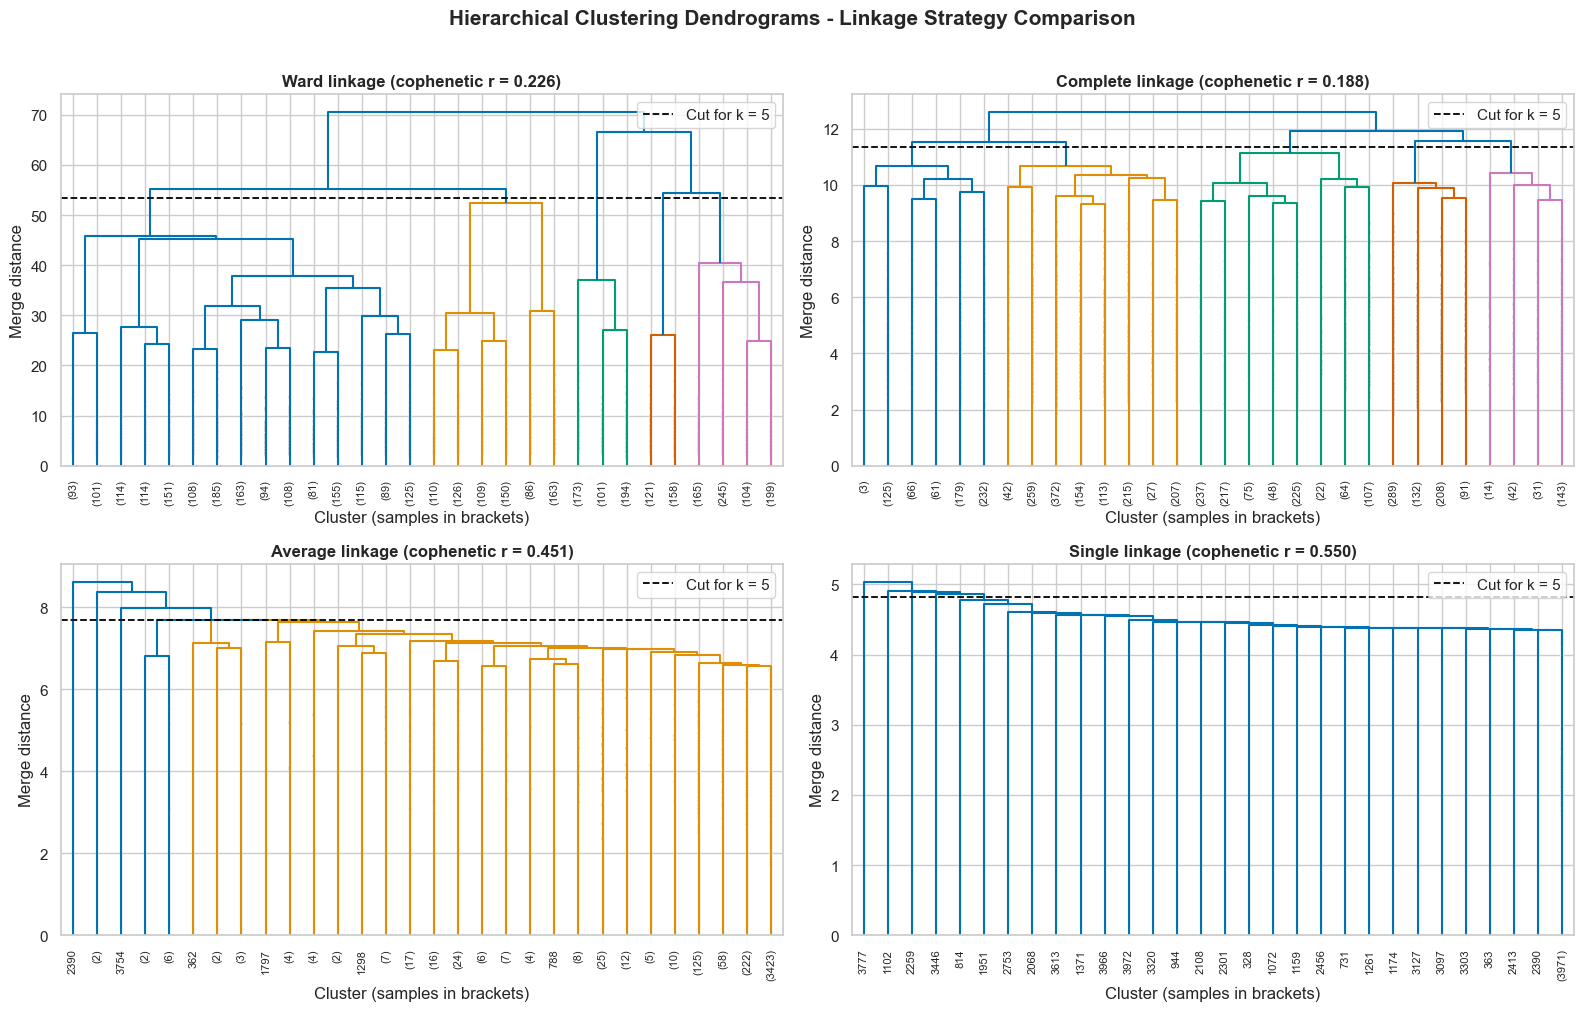

In [54]:
def cut_height(Z, k):
    """Height that cuts the dendrogram into exactly k clusters."""
    return (Z[-(k - 1), 2] + Z[-k, 2]) / 2


# Single linkage "chains" points into a very deep tree and SciPy's dendrogram code is recursive
sys.setrecursionlimit(max(sys.getrecursionlimit(), 20000))
set_link_color_palette(sns.color_palette("colorblind").as_hex())

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, method in zip(axes.ravel(), linkage_methods):
    Z = Z_by_method[method]
    threshold = cut_height(Z, K_CLUSTERS)
    dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=threshold,
               leaf_rotation=90, leaf_font_size=8, show_contracted=True, ax=ax)
    ax.axhline(threshold, color="black", ls="--", lw=1.3, label=f"Cut for k = {K_CLUSTERS}")
    coph = linkage_comparison.set_index("Linkage").loc[method, "Cophenetic Corr."]
    ax.set_title(f"{method.capitalize()} linkage (cophenetic r = {coph:.3f})", fontsize=12, weight="bold")
    ax.set_xlabel("Cluster (samples in brackets)")
    ax.set_ylabel("Merge distance")
    ax.legend(loc="upper right")
plt.suptitle("Hierarchical Clustering Dendrograms - Linkage Strategy Comparison", fontsize=15, weight="bold", y=1.01)
plt.tight_layout()
plt.show()

### F3.2 — Dendrogram of the Selected Linkage

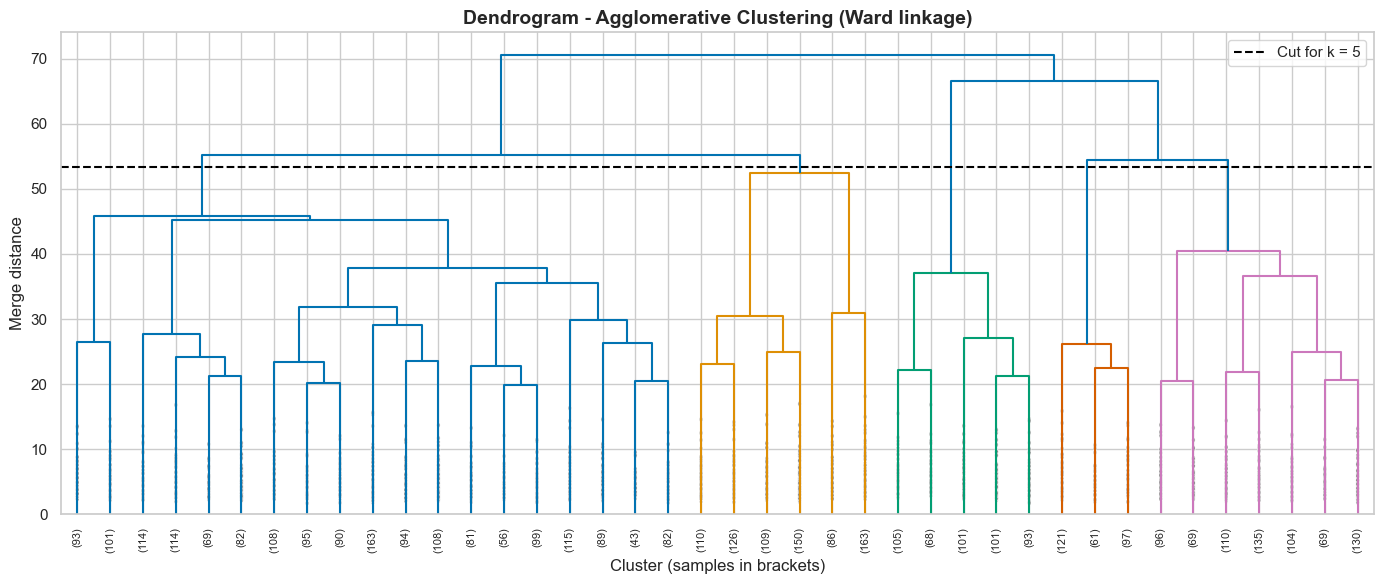

In [55]:
Z_best = Z_by_method[best_linkage]
threshold_best = cut_height(Z_best, K_CLUSTERS)

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(Z_best, truncate_mode="lastp", p=40, color_threshold=threshold_best,
           leaf_rotation=90, leaf_font_size=8, show_contracted=True, ax=ax)
ax.axhline(threshold_best, color="black", ls="--", lw=1.5, label=f"Cut for k = {K_CLUSTERS}")
ax.set_title(f"Dendrogram - Agglomerative Clustering ({best_linkage.capitalize()} linkage)", fontsize=14, weight="bold")
ax.set_xlabel("Cluster (samples in brackets)")
ax.set_ylabel("Merge distance")
ax.legend()
plt.tight_layout()
plt.show()

set_link_color_palette(None)   # restore SciPy's default palette

## F4 — Clustering Evaluation Metrics (Both Algorithms)

Silhouette Score, Davies-Bouldin Index and Calinski-Harabasz Index are computed for **both** algorithms on the **same** scaled sample and the same *k*. These are *internal* metrics: they judge how compact and well-separated the clusters are using only the features, without any labels.

In [56]:
clustering_results = pd.DataFrame([
    {"Algorithm": f"K-Means (k={K_CLUSTERS})", **evaluate_clustering(X_cluster, kmeans_labels)},
    {"Algorithm": f"Agglomerative ({best_linkage} linkage, k={K_CLUSTERS})", **evaluate_clustering(X_cluster, agglo_labels)},
])

display(clustering_results.round(4))
clustering_results.round(4).to_csv(f"{RESULTS_DIR}/clustering_metrics.csv", index=False)

print("Best algorithm per metric:")
print("  Silhouette (higher)        :", clustering_results.loc[clustering_results["Silhouette Score"].idxmax(), "Algorithm"])
print("  Davies-Bouldin (lower)     :", clustering_results.loc[clustering_results["Davies-Bouldin Index"].idxmin(), "Algorithm"])
print("  Calinski-Harabasz (higher) :", clustering_results.loc[clustering_results["Calinski-Harabasz Index"].idxmax(), "Algorithm"])

sil_max = clustering_results["Silhouette Score"].max()
if sil_max < 0.25:
    print(f"\nNote: the best silhouette ({sil_max:.3f}) is below 0.25, which indicates weak cluster structure - "
          "the groups overlap and boundaries between them are soft.")
elif sil_max < 0.5:
    print(f"\nNote: the best silhouette ({sil_max:.3f}) indicates moderate, reasonably separated structure.")
else:
    print(f"\nNote: the best silhouette ({sil_max:.3f}) indicates strong cluster structure.")

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means (k=5),0.0564,3.0154,203.3723
1,"Agglomerative (ward linkage, k=5)",0.0214,4.1216,106.4723


Best algorithm per metric:
  Silhouette (higher)        : K-Means (k=5)
  Davies-Bouldin (lower)     : K-Means (k=5)
  Calinski-Harabasz (higher) : K-Means (k=5)

Note: the best silhouette (0.056) is below 0.25, which indicates weak cluster structure - the groups overlap and boundaries between them are soft.


### Silhouette Score

## F5 — Cluster Visualisation: PCA (2 Components) & t-SNE

### F5.1 — PCA 2-D Scatter Plot for Every Algorithm

**Why we plot this:** the clustering lives in ~20 dimensions, which cannot be drawn directly. PCA projects the data onto the two directions of maximum variance so cluster membership can be inspected visually. Because PCA is linear and keeps only two components, clusters that are separated along other directions can look overlapped. The percentage in each axis label is the variance explained by that component.

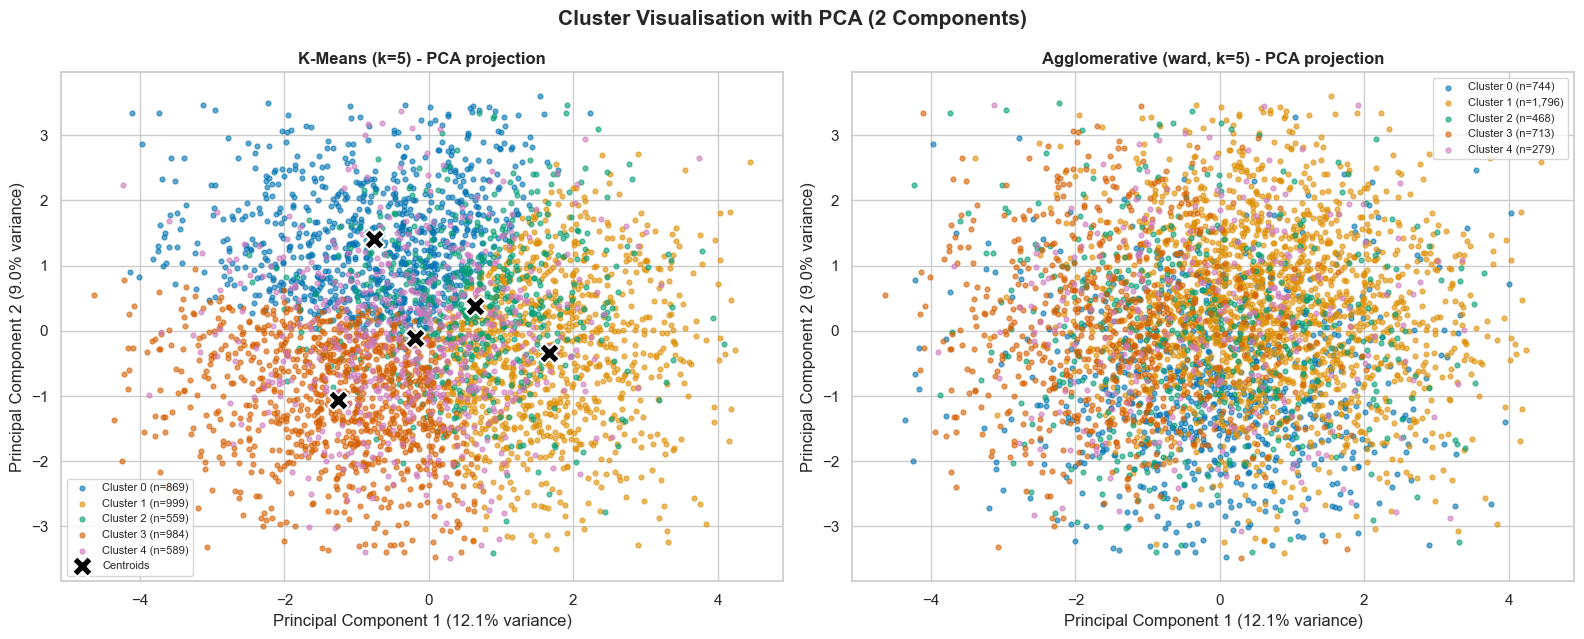

Variance captured by the two components: 21.1% (the rest of the structure is not visible in these plots).


In [57]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_cluster)
pc1, pc2 = pca.explained_variance_ratio_ * 100
pca_centers = pca.transform(kmeans_model.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
scatter_clusters(axes[0], X_pca, kmeans_labels,
                 f"K-Means (k={K_CLUSTERS}) - PCA projection",
                 f"Principal Component 1 ({pc1:.1f}% variance)",
                 f"Principal Component 2 ({pc2:.1f}% variance)", centers=pca_centers)
scatter_clusters(axes[1], X_pca, agglo_labels,
                 f"Agglomerative ({best_linkage}, k={K_CLUSTERS}) - PCA projection",
                 f"Principal Component 1 ({pc1:.1f}% variance)",
                 f"Principal Component 2 ({pc2:.1f}% variance)")
plt.suptitle("Cluster Visualisation with PCA (2 Components)", fontsize=15, weight="bold")
plt.tight_layout()
plt.show()

print(f"Variance captured by the two components: {pc1 + pc2:.1f}% "
      f"(the rest of the structure is not visible in these plots).")

### F5.2 — t-SNE Visualisation (Both Algorithms)

**Why we plot this:** t-SNE is a non-linear embedding that preserves *local neighbourhoods*, so it can reveal groups that a linear PCA projection hides. The same embedding is coloured twice, once per algorithm. t-SNE axes have no physical meaning and distances *between* far-apart blobs should not be over-interpreted; it is used here only as a complementary visual check.

it can reveal groups that a linear PCA projection hides.

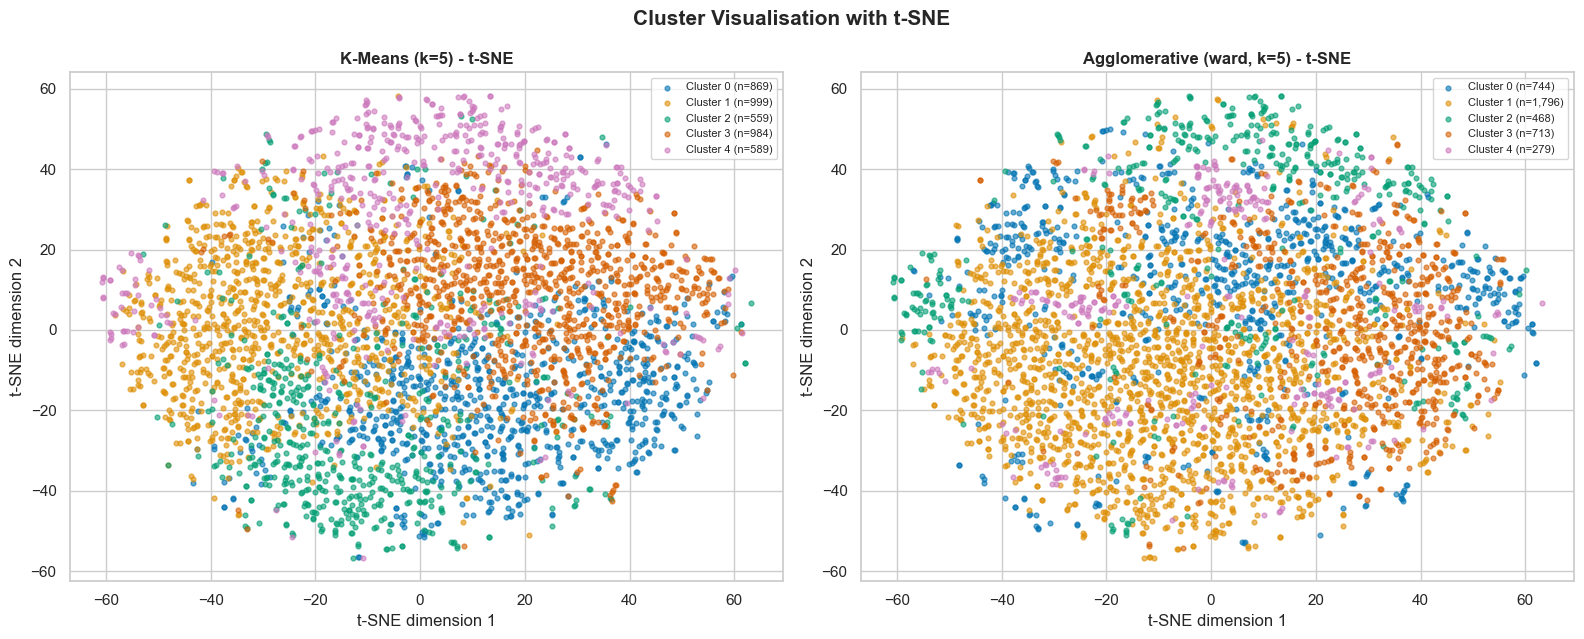

In [58]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_cluster)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
scatter_clusters(axes[0], X_tsne, kmeans_labels,
                 f"K-Means (k={K_CLUSTERS}) - t-SNE", "t-SNE dimension 1", "t-SNE dimension 2")
scatter_clusters(axes[1], X_tsne, agglo_labels,
                 f"Agglomerative ({best_linkage}, k={K_CLUSTERS}) - t-SNE", "t-SNE dimension 1", "t-SNE dimension 2")
plt.suptitle("Cluster Visualisation with t-SNE", fontsize=15, weight="bold")
plt.tight_layout()
plt.show()

## F6 — Cluster Interpretation & Post-hoc Validation

### F6.1 — Cluster Profiles (Standardised Feature Means)

**Why we plot this:** to describe what makes each cluster different. Each cell shows the cluster's mean of a feature in standard-deviation units (z-score): positive (red) means above the overall average, negative (blue) below. Features with the strongest colours characterise that cluster.

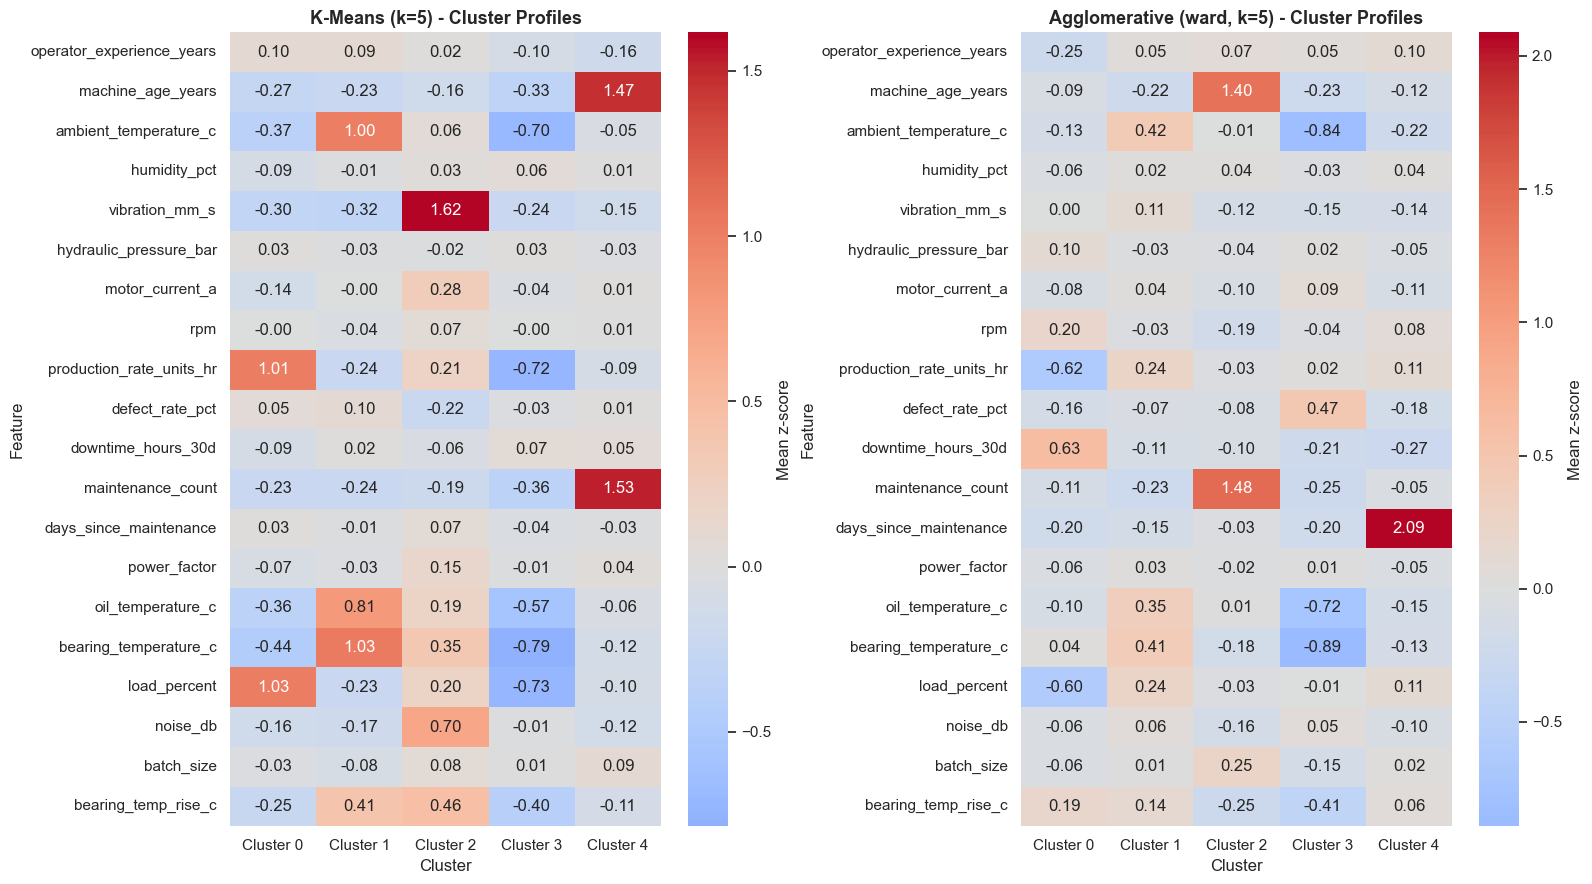

Cluster 0: load_percent (+1.03), production_rate_units_hr (+1.01), bearing_temperature_c (-0.44)
Cluster 1: bearing_temperature_c (+1.03), ambient_temperature_c (+1.00), oil_temperature_c (+0.81)
Cluster 2: vibration_mm_s (+1.62), noise_db (+0.70), bearing_temp_rise_c (+0.46)
Cluster 3: bearing_temperature_c (-0.79), load_percent (-0.73), production_rate_units_hr (-0.72)
Cluster 4: maintenance_count (+1.53), machine_age_years (+1.47), operator_experience_years (-0.16)


In [59]:
scaled_df = pd.DataFrame(X_cluster, columns=cluster_features)  # winsorised + standardised
profile_kmeans = scaled_df.groupby(kmeans_labels).mean().T
profile_agglo = scaled_df.groupby(agglo_labels).mean().T
profile_kmeans.columns = [f"Cluster {c}" for c in profile_kmeans.columns]
profile_agglo.columns = [f"Cluster {c}" for c in profile_agglo.columns]

fig, axes = plt.subplots(1, 2, figsize=(16, 9))
sns.heatmap(profile_kmeans, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=axes[0], cbar_kws={"label": "Mean z-score"})
axes[0].set_title(f"K-Means (k={K_CLUSTERS}) - Cluster Profiles", fontsize=13, weight="bold")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Feature")
sns.heatmap(profile_agglo, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=axes[1], cbar_kws={"label": "Mean z-score"})
axes[1].set_title(f"Agglomerative ({best_linkage}, k={K_CLUSTERS}) - Cluster Profiles", fontsize=13, weight="bold")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Feature")
plt.tight_layout()
plt.show()

# Most distinguishing features per K-Means cluster (largest absolute z-score)
for c in profile_kmeans.columns:
    top3 = profile_kmeans[c].abs().sort_values(ascending=False).head(3).index
    desc = ", ".join(f"{f} ({profile_kmeans.loc[f, c]:+.2f})" for f in top3)
    print(f"{c}: {desc}")

### F6.2 — Post-hoc Validation Against `maintenance_risk`

Only **now** are the ground-truth risk labels brought in. Two external metrics measure agreement between clusters and labels, regardless of how clusters are numbered:

* **Adjusted Rand Index (ARI):** 1 = identical partitions, ≈ 0 = no better than random labelling.
* **Normalised Mutual Information (NMI):** 0 = clusters carry no information about the labels, 1 = perfect agreement.

The cross-tabulation shows, for each cluster, the share of Low / Medium / High risk machines.

,Algorithm,Adjusted Rand Index,Normalised Mutual Info
0,K-Means (k=5),0.0082,0.0062
1,"Agglomerative (ward, k=5)",0.0414,0.0589


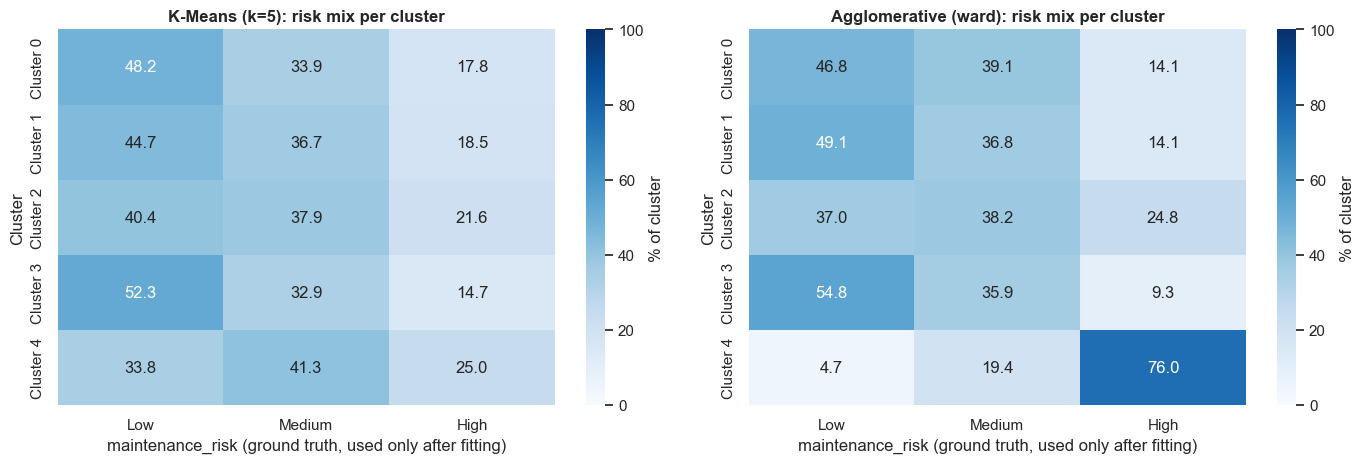

Overall risk mix in the sample: {'Low': 45.2, 'Medium': 36.0, 'High': 18.8}
Interpretation guide: if a cluster's risk mix differs clearly from the overall mix, the cluster is informative about maintenance risk; if it matches the overall mix, it is not.


In [60]:
validation_rows = []
for name, labels in [(f"K-Means (k={K_CLUSTERS})", kmeans_labels),
                     (f"Agglomerative ({best_linkage}, k={K_CLUSTERS})", agglo_labels)]:
    validation_rows.append({
        "Algorithm": name,
        "Adjusted Rand Index": adjusted_rand_score(risk_labels_for_validation, labels),
        "Normalised Mutual Info": normalized_mutual_info_score(risk_labels_for_validation, labels),
    })
validation_df = pd.DataFrame(validation_rows)
display(validation_df.round(4))
validation_df.round(4).to_csv(f"{RESULTS_DIR}/clustering_external_validation.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (name, labels) in zip(axes, [(f"K-Means (k={K_CLUSTERS})", kmeans_labels),
                                     (f"Agglomerative ({best_linkage})", agglo_labels)]):
    ct = pd.crosstab(labels, risk_labels_for_validation.values, normalize="index") * 100
    ct = ct[[c for c in ["Low", "Medium", "High"] if c in ct.columns]]
    ct.index = [f"Cluster {c}" for c in ct.index]
    sns.heatmap(ct, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, ax=ax, cbar_kws={"label": "% of cluster"})
    ax.set_title(f"{name}: risk mix per cluster", fontsize=12, weight="bold")
    ax.set_xlabel("maintenance_risk (ground truth, used only after fitting)")
    ax.set_ylabel("Cluster")
plt.tight_layout()
plt.show()

overall = risk_labels_for_validation.value_counts(normalize=True).mul(100).round(1).to_dict()
print("Overall risk mix in the sample:", overall)
print("Interpretation guide: if a cluster's risk mix differs clearly from the overall mix, the cluster is "
      "informative about maintenance risk; if it matches the overall mix, it is not.")

### clustering does not consider machine risk , which is what want exactly  

---
# Section F7 — Clustering Track Summary & Results Validation

Summary of unsupervised pattern discovery across machine profiles.

In [61]:
print("=" * 78)
print("CLUSTERING TRACK SUMMARY - SMART MANUFACTURING ML PIPELINE")
print("=" * 78)

best_sil = clustering_results.loc[clustering_results["Silhouette Score"].idxmax()]
print("\n[CLUSTERING]  Unsupervised, risk labels used only for post-hoc validation")
print(f"  Samples / features  : {X_cluster.shape[0]:,} / {X_cluster.shape[1]}")
print(f"  Selected k          : {K_CLUSTERS} (elbow curve)")
print(f"  Best silhouette     : {best_sil['Algorithm']} ({best_sil['Silhouette Score']:.4f})")
print(f"  Davies-Bouldin      : {best_sil['Davies-Bouldin Index']:.4f}")
print(f"  Calinski-Harabasz   : {best_sil['Calinski-Harabasz Index']:.4f}")
print("=" * 78)

# ---- Saved clustering artefacts ----
print("\nClustering results saved to:")
if os.path.exists(RESULTS_DIR):
    for fname in sorted(os.listdir(RESULTS_DIR)):
        if "clustering" in fname or "agglomerative" in fname:
            print(f"  {RESULTS_DIR}/{fname}")


CLUSTERING TRACK SUMMARY - SMART MANUFACTURING ML PIPELINE

[CLUSTERING]  Unsupervised, risk labels used only for post-hoc validation
  Samples / features  : 4,000 / 20
  Selected k          : 5 (elbow curve)
  Best silhouette     : K-Means (k=5) (0.0564)
  Davies-Bouldin      : 3.0154
  Calinski-Harabasz   : 203.3723

Clustering results saved to:
  ..\results/agglomerative_linkage_comparison.csv
  ..\results/clustering_external_validation.csv
  ..\results/clustering_metrics.csv



## F7.1 — Executive Summary

This final summary consolidates the clustering design, model-selection evidence, cluster sizes,
post-hoc risk validation and the main limitation. It is generated from the objects created above
so that the reported values stay synchronized with the notebook run.


In [62]:
print("=" * 90)
print("EXECUTIVE SUMMARY - MACHINE OPERATING PROFILE CLUSTERING")
print("=" * 90)

best_internal = clustering_results.loc[
    clustering_results["Silhouette Score"].idxmax()
]
best_external = validation_df.loc[
    validation_df["Adjusted Rand Index"].idxmax()
]
two_component_variance = float(pca.explained_variance_ratio_[:2].sum())

print("\n1. DATA AND DESIGN")
print(f"   Records analysed       : {X_cluster.shape[0]:,}")
print(f"   Clustering features    : {X_cluster.shape[1]} numeric features")
print("   Pre-processing         : 1st-99th percentile winsorisation, then StandardScaler")
print("   Targets used for fit   : none; maintenance_risk was held out until validation")

print("\n2. MODEL SELECTION")
print(f"   Geometric elbow k      : {elbow_k}")
print(f"   Highest silhouette k   : {silhouette_best_k}")
print(f"   Selected k             : {K_CLUSTERS} (used by both algorithms)")
print(f"   Best internal result   : {best_internal['Algorithm']}")

internal_view = clustering_results[[
    "Algorithm", "Silhouette Score", "Davies-Bouldin Index",
    "Calinski-Harabasz Index"
]].round(4)
display(internal_view)

print("3. CLUSTER SIZES")
cluster_sizes = pd.DataFrame({
    "K-Means": pd.Series(kmeans_labels).value_counts().sort_index(),
    "Agglomerative": pd.Series(agglo_labels).value_counts().sort_index(),
}).fillna(0).astype(int)
cluster_sizes.index = [f"Cluster {i}" for i in cluster_sizes.index]
display(cluster_sizes)

print("4. POST-HOC RISK VALIDATION")
print("   Risk labels were not used to create the clusters.")
print(f"   Best ARI result        : {best_external['Algorithm']} ({best_external['Adjusted Rand Index']:.4f})")
best_nmi = validation_df.loc[validation_df["Normalised Mutual Info"].idxmax()]
print(f"   Best NMI result        : {best_nmi['Algorithm']} ({best_nmi['Normalised Mutual Info']:.4f})")
display(validation_df.round(4))

print("5. INTERPRETATION")
if best_internal["Silhouette Score"] < 0.25:
    print("   The silhouette score is weak (< 0.25): the operating profiles overlap substantially.")
    print("   Clusters should therefore be treated as exploratory segments, not sharply separated machine types.")
elif best_internal["Silhouette Score"] < 0.5:
    print("   The silhouette score indicates moderate separation; segments are useful but overlap remains.")
else:
    print("   The silhouette score indicates comparatively strong separation between segments.")
print(f"   PCA's first two components explain {two_component_variance:.1%} of variance; PCA plots are only a 2-D view.")
print("   Use the cluster-profile heatmap and risk-mix chart for operational interpretation; do not infer causality.")

print("6. OUTPUTS")
if os.path.exists(RESULTS_DIR):
    for fname in sorted(os.listdir(RESULTS_DIR)):
        if "clustering" in fname or "agglomerative" in fname:
            print(f"   {RESULTS_DIR}/{fname}")
print("=" * 90)

EXECUTIVE SUMMARY - MACHINE OPERATING PROFILE CLUSTERING

1. DATA AND DESIGN
   Records analysed       : 4,000
   Clustering features    : 20 numeric features
   Pre-processing         : 1st-99th percentile winsorisation, then StandardScaler
   Targets used for fit   : none; maintenance_risk was held out until validation

2. MODEL SELECTION
   Geometric elbow k      : 5
   Highest silhouette k   : 2
   Selected k             : 5 (used by both algorithms)
   Best internal result   : K-Means (k=5)


,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means (k=5),0.0564,3.0154,203.3723
1,"Agglomerative (ward linkage, k=5)",0.0214,4.1216,106.4723


3. CLUSTER SIZES


,K-Means,Agglomerative
Cluster 0,869,744
Cluster 1,999,1796
Cluster 2,559,468
Cluster 3,984,713
Cluster 4,589,279


4. POST-HOC RISK VALIDATION
   Risk labels were not used to create the clusters.
   Best ARI result        : Agglomerative (ward, k=5) (0.0414)
   Best NMI result        : Agglomerative (ward, k=5) (0.0589)


,Algorithm,Adjusted Rand Index,Normalised Mutual Info
0,K-Means (k=5),0.0082,0.0062
1,"Agglomerative (ward, k=5)",0.0414,0.0589


5. INTERPRETATION
   The silhouette score is weak (< 0.25): the operating profiles overlap substantially.
   Clusters should therefore be treated as exploratory segments, not sharply separated machine types.
   PCA's first two components explain 21.1% of variance; PCA plots are only a 2-D view.
   Use the cluster-profile heatmap and risk-mix chart for operational interpretation; do not infer causality.
6. OUTPUTS
   ..\results/agglomerative_linkage_comparison.csv
   ..\results/clustering_external_validation.csv
   ..\results/clustering_metrics.csv
